# Redes Neuronales para Series de Tiempo
### MLP y LSTM con rezagos de la serie y de variables de Fourier

**Objetivo de la clase.** Pronosticar la presión atmosférica horaria (hPa) medida en el aeropuerto internacional de Pekín usando redes neuronales: un **perceptrón multicapa (MLP)** y una **red LSTM**. Construimos todo paso a paso con `pandas`, `scikit-learn` y `keras`, y pronosticamos **1 y 2 horas adelante**.

**Al terminar la clase el estudiante podrá:**
1. Usar la ACF, la PACF y el periodograma para decidir qué rezagos y qué ciclos modelar.
2. Construir variables de Fourier (senos y cosenos) para representar ciclos y usar sus rezagos como variables explicativas.
3. Transformar una serie de tiempo en un problema de aprendizaje supervisado para un MLP (tabla) y para una LSTM (ventanas).
4. Seguir siempre el mismo esquema: **modelo elemental → búsqueda de hiperparámetros con validación → validación cruzada secuencial → modelo final → prueba**.
5. Pronosticar 2 pasos adelante con las tres estrategias: **recursiva, directa y *one-shot***.
6. Poner el modelo en producción y pronosticar las 2 horas siguientes al último dato.

**Hoja de ruta**

| Sección | Contenido |
|---|---|
| 1 | Datos y exploración (ACF, PACF, periodograma) |
| 2 | Variables de Fourier para los ciclos diario y anual |
| 3 | De serie a tabla: rezagos de la presión y de las variables de Fourier |
| 4 | División temporal entrenamiento / validación / prueba, estandarización y errores a 1 y 2 pasos |
| 5 | Modelo de referencia: persistencia |
| 6 | MLP: referencia lineal, modelo elemental, búsqueda de hiperparámetros, validación cruzada y modelo final |
| 7 | LSTM: el mismo esquema |
| 8 | Pronóstico 2 pasos adelante: recursivo, directo y *one-shot* |
| 9 | Etapa de producción: pronóstico de las 2 horas siguientes |
| 10 | Comparación final y conclusiones |
| Anexo | Compendio de las funciones del cuaderno: objetivo, funcionamiento y argumentos |

Al final de cada sección hay **ejercicios** (✏️).

> **Tiempo de ejecución.** Entrenar redes es más costoso que entrenar árboles. Ejecutar todo el cuaderno toma del orden de 15 a 30 minutos en un computador portátil (sin GPU).

In [1]:
# Librerías
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # oculta mensajes informativos de TensorFlow
os.environ["GRPC_VERBOSITY"] = "NONE"
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import pacf

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

import tensorflow as tf
import keras
import keras_tuner as kt
import sklearn
tf.get_logger().setLevel("ERROR")

plt.rcParams["figure.figsize"] = (10, 4)
SEMILLA = 123

print("tensorflow", tf.__version__, "| keras", keras.__version__, "| keras_tuner", kt.__version__,
      "| scikit-learn", sklearn.__version__)

tensorflow 2.21.0 | keras 3.12.1 | keras_tuner 1.4.8 | scikit-learn 1.7.2


Usaremos una única función para evaluar todos los modelos, así todas las comparaciones usan las mismas métricas, ambas en **hPa** (las unidades de la serie):

- **RECM** (raíz del error cuadrático medio). Menor es mejor.
- **EAM** (error absoluto medio): el error típico de un pronóstico, menos sensible a errores grandes. Menor es mejor.

**¿Por qué no usamos el R²?** La presión cambia mucho a lo largo del año, pero muy poco de una hora a la siguiente. Cualquier modelo razonable, incluso "la próxima hora será igual a la actual", obtiene un R² cercano a 1, así que el R² no permite distinguir entre modelos.

In [2]:
def evaluar(y_real, y_pred):
    # Devuelve la RECM y el EAM (en hPa) de un conjunto de predicciones.
    return {"RECM": root_mean_squared_error(y_real, y_pred), "EAM": mean_absolute_error(y_real, y_pred)}

# 1. Datos y exploración

El archivo contiene datos horarios de la Embajada de EE. UU. en Pekín (PM2.5) junto con variables meteorológicas del aeropuerto internacional de Pekín, entre el 1 de enero de 2010 y el 31 de diciembre de 2014. Trabajamos con la **presión atmosférica** (`PRES`, en hPa).

In [3]:
df = pd.read_csv("PRSA_data_2010.1.1-2014.12.31.csv")
fechas = pd.to_datetime(df[["year", "month", "day", "hour"]])
pres = pd.Series(df["PRES"].values, index=pd.DatetimeIndex(fechas, freq="h"), name="pres")

print(f"Observaciones: {len(pres)}  |  desde {pres.index[0]} hasta {pres.index[-1]}  |  datos faltantes: {pres.isna().sum()}")
pres.describe().round(2)

Observaciones: 43824  |  desde 2010-01-01 00:00:00 hasta 2014-12-31 23:00:00  |  datos faltantes: 0


count    43824.00
mean      1016.45
std         10.27
min        991.00
25%       1008.00
50%       1016.00
75%       1025.00
max       1046.00
Name: pres, dtype: float64

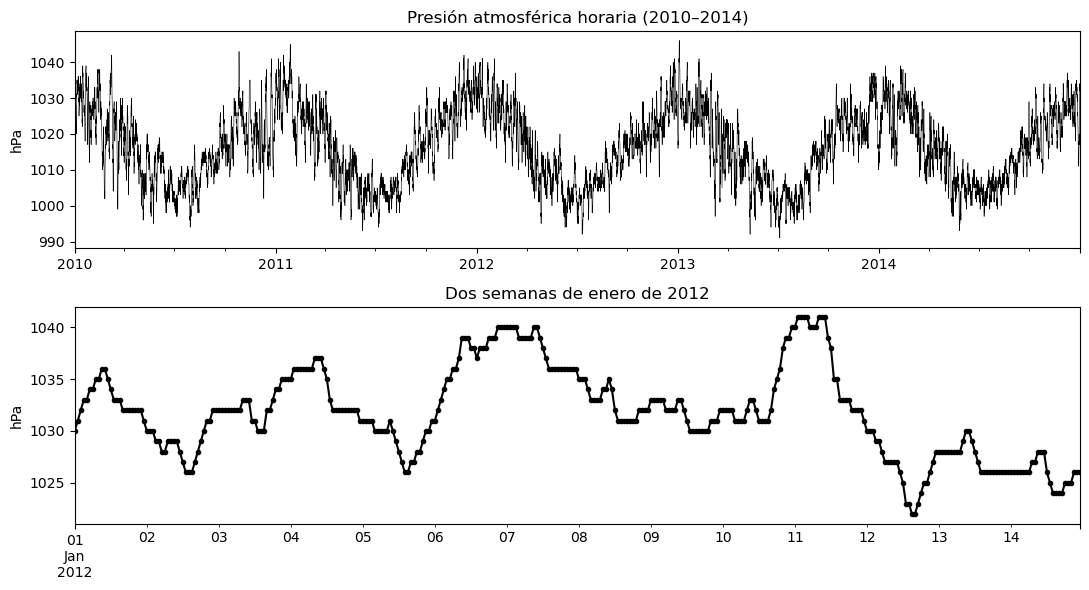

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
pres.plot(ax=ax[0], lw=0.4, color="black", title="Presión atmosférica horaria (2010–2014)", ylabel="hPa")
pres["2012-01-01":"2012-01-14"].plot(ax=ax[1], marker=".", color="black", title="Dos semanas de enero de 2012", ylabel="hPa")
plt.tight_layout(); plt.show()

La serie completa muestra un **ciclo anual** marcado: presión alta en invierno y baja en verano. En la ampliación de dos semanas se ve que la presión cambia **lentamente** de una hora a la siguiente y que hay una pequeña **oscilación diaria**. Note además que los valores están **redondeados a 1 hPa** (los escalones del segundo gráfico).

## 1.1 ACF y PACF

- La **ACF** muestra la correlación entre $y_t$ y $y_{t-k}$.
- La **PACF** muestra la correlación entre $y_t$ y $y_{t-k}$ *descontando* el efecto de los rezagos intermedios.

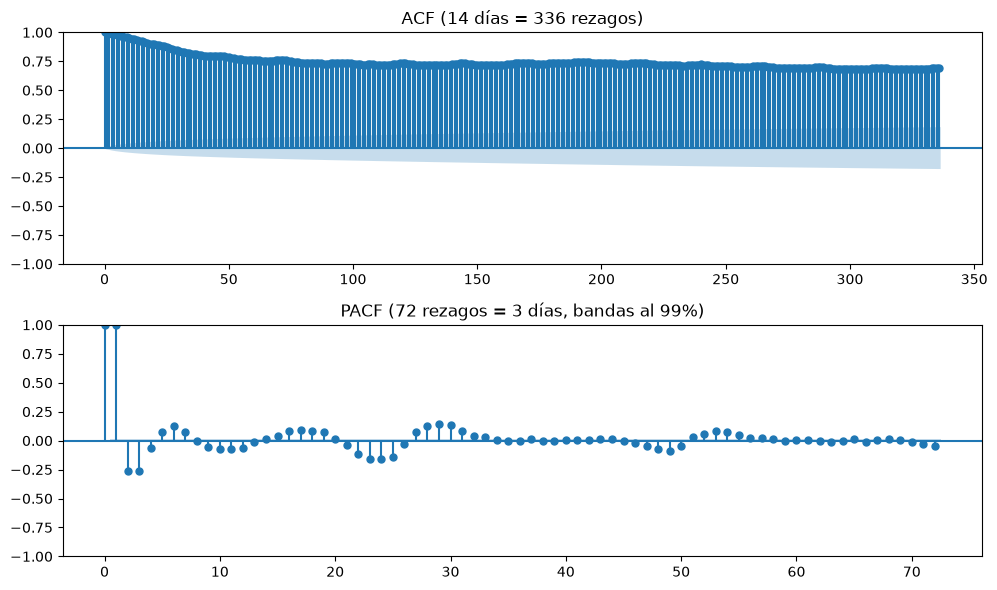

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
plot_acf(pres, lags=24 * 14, ax=ax[0], title="ACF (14 días = 336 rezagos)",fft=True)
plot_pacf(pres, lags=72, method="ywm", alpha=0.01, ax=ax[1], title="PACF (72 rezagos = 3 días, bandas al 99%)")
plt.tight_layout(); plt.show()

Igual que en la clase de árboles, leemos la PACF de forma objetiva: un coeficiente es significativo al 99% si $|\hat\phi_{kk}| > 2.58/\sqrt{T}$.

In [6]:
T = len(pres)
pacf_valores = pacf(pres, nlags=72, method="ywm")
umbral = 2.58 / np.sqrt(T)

tabla_pacf = pd.DataFrame({"PACF": pacf_valores[1:], "significativo": np.abs(pacf_valores[1:]) > umbral},
                          index=pd.RangeIndex(1, 73, name="rezago"))
print(f"Umbral: {umbral:.4f}")
print("Rezagos NO significativos entre 1 y 72:", tabla_pacf.index[~tabla_pacf["significativo"]].tolist())
tabla_pacf.head(8).round(3)

Umbral: 0.0123
Rezagos NO significativos entre 1 y 72: [8, 34, 35, 36, 38, 39, 40, 41, 42, 43, 45, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 69]


,PACF,significativo
rezago,,
1,0.998,True
2,-0.259,True
3,-0.259,True
4,-0.067,True
5,0.076,True
6,0.125,True
7,0.075,True
8,-0.006,False


## 1.2 Periodograma: ¿qué ciclos hay?

Un pico en la frecuencia $f$ indica un ciclo de **periodo $1/f$ horas**. Graficamos contra el periodo, en escala logarítmica, y marcamos 12 horas, 24 horas y un año (8766 horas).

Periodos (horas) con mayor potencia: [8764.8 2921.6   24.  4382.4 1685.5 3371.1   12.   509.6]


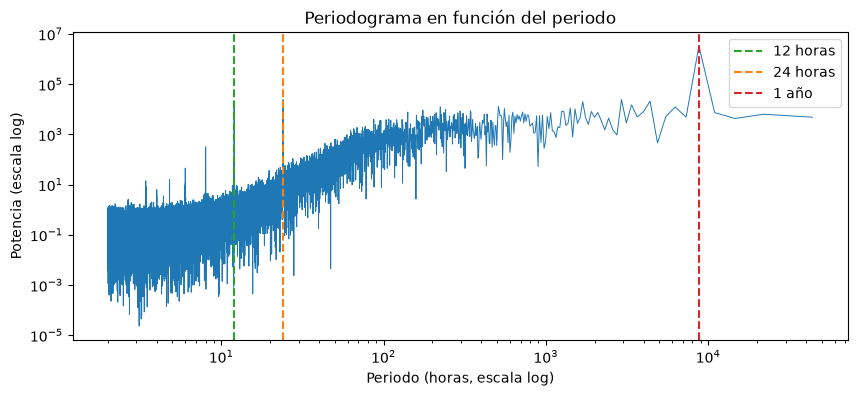

In [7]:
frecuencias, potencia = signal.periodogram(pres.values)
frecuencias, potencia = frecuencias[1:], potencia[1:]      # se omite la frecuencia 0 (la media)
periodos = 1 / frecuencias

top = np.argsort(potencia)[::-1][:8]
print("Periodos (horas) con mayor potencia:", np.round(periodos[top], 1))

plt.loglog(periodos, potencia, lw=0.7)
for P, color, etiqueta in [(12, "tab:green", "12 horas"), (24, "tab:orange", "24 horas"), (8766, "tab:red", "1 año")]:
    plt.axvline(P, color=color, ls="--", label=etiqueta)
plt.xlabel("Periodo (horas, escala log)"); plt.ylabel("Potencia (escala log)")
plt.title("Periodograma en función del periodo")
plt.legend(); plt.show()

**¿Qué observamos?**

- La **PACF** tiene un rezago 1 casi igual a 1: la presión de la hora anterior es, con diferencia, la mejor información. Después hay muchos rezagos significativos que **oscilan con periodo cercano a 24 horas**, la huella del ciclo diario.
- El **periodograma** tiene su pico principal en **8764.8 horas ≈ 365.2 días** (ciclo anual). Aparecen también 4382.4 y 2921.6 horas, que son la mitad y la tercera parte del año (armónicos del ciclo anual). Además hay picos en **24 horas** y en **12 horas** (ciclo diario y su primer armónico).

**Decisión de modelación.**

| Ingrediente | Elección | Qué captura |
|---|---|---|
| Rezagos de la presión | 1, 2, …, 24 | La inercia de las últimas horas y un día completo de historia |
| Variables de Fourier | seno y coseno con periodos 24 h, 12 h y 1 año | Los ciclos detectados por el periodograma |
| Rezagos de Fourier (las variables de Fourier en cada hora de la ventana) | 1, 2, …, 24 (los mismos de la presión) | En qué parte del día y del año está cada hora de la ventana |

> ✏️ **Ejercicio 1.** El periodograma de la serie completa tiene mucha variabilidad. Use `signal.welch(pres.values, nperseg=24*30)` y grafique contra el periodo. ¿Se detecta el ciclo de 24 horas? ¿Y el ciclo anual? Explique por qué el resultado depende de `nperseg`.

# 2. Variables de Fourier para los ciclos

Un ciclo de periodo $P$ (en horas) se representa con dos variables **determinísticas**:

$$s_t = \sin\!\left(\frac{2\pi t}{P}\right), \qquad c_t = \cos\!\left(\frac{2\pi t}{P}\right),$$

donde $t$ son las horas transcurridas desde un origen fijo (aquí, el 1 de enero de 2010 a las 00:00).

- **¿Por qué seno y coseno?** Cualquier onda de periodo $P$, sin importar en qué momento alcance su máximo (su *fase*), se escribe como $a\,s_t + b\,c_t$. El modelo aprende $a$ y $b$. Además, el par $(s_t, c_t)$ ubica cada hora en un círculo: las 23:00 y las 00:00 quedan cerca, como debe ser.
- **Son conocidas para cualquier fecha futura.** No hay que pronosticarlas. Esto será clave en el pronóstico recursivo (sección 8) y en producción (sección 9).

In [5]:
PERIODOS = {"24h": 24, "12h": 12, "anual": 365.2425 * 24}
ORIGEN = pd.Timestamp("2010-01-01 00:00")

def variables_fourier(fechas):
    # Devuelve un DataFrame con el seno y el coseno de cada periodo para las fechas dadas.
    horas = np.asarray((fechas - ORIGEN) / pd.Timedelta(hours=1))
    F = pd.DataFrame(index=fechas)
    for nombre, P in PERIODOS.items():
        F[f"sin_{nombre}"] = np.sin(2 * np.pi * horas / P)
        F[f"cos_{nombre}"] = np.cos(2 * np.pi * horas / P)
    return F

fourier = variables_fourier(pres.index)
fourier.head()

,sin_24h,cos_24h,sin_12h,cos_12h,sin_anual,cos_anual
2010-01-01 00:00:00,0.000000,1.000000,0.000000,1.000000e+00,0.000000,1.000000
2010-01-01 01:00:00,0.258819,0.965926,0.500000,8.660254e-01,0.000717,1.000000
2010-01-01 02:00:00,0.500000,0.866025,0.866025,5.000000e-01,0.001434,0.999999
2010-01-01 03:00:00,0.707107,0.707107,1.000000,6.123234e-17,0.002150,0.999998
2010-01-01 04:00:00,0.866025,0.500000,0.866025,-5.000000e-01,0.002867,0.999996


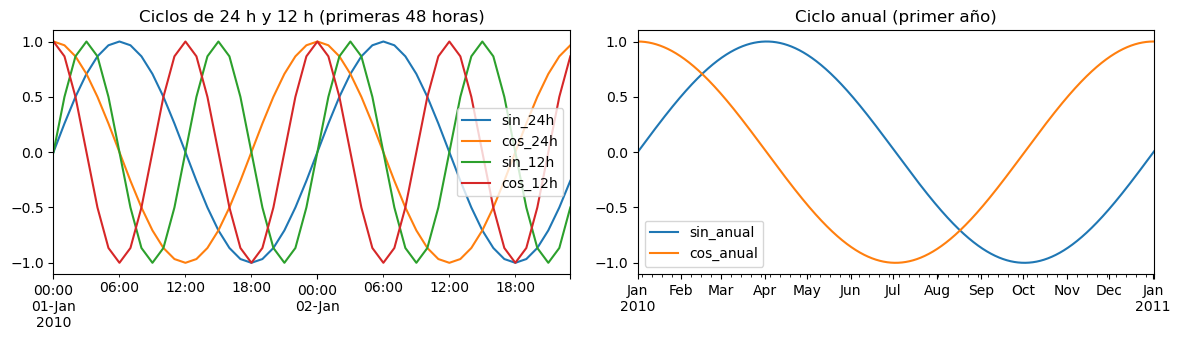

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
fourier.iloc[:48, :4].plot(ax=ax[0], title="Ciclos de 24 h y 12 h (primeras 48 horas)")
fourier.iloc[:24 * 366, 4:].plot(ax=ax[1], title="Ciclo anual (primer año)")
ax[0].set_xlabel(""); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

**¿Cuánto explican los ciclos por sí solos?** Como exploración, ajustamos una regresión lineal de la presión sobre las seis variables de Fourier (sin rezagos de la presión).

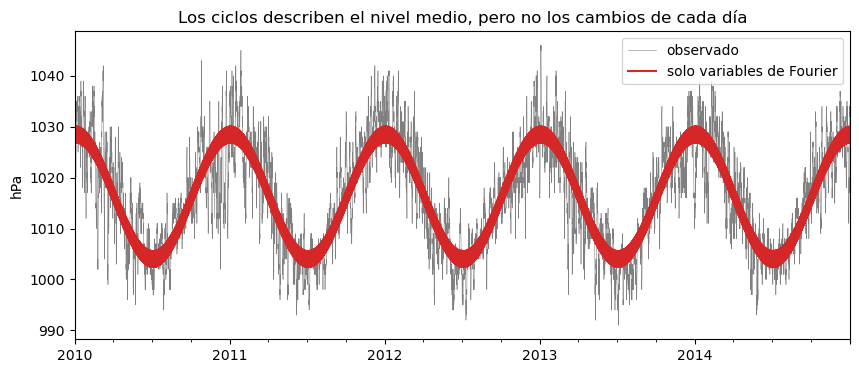

RECM usando solo los ciclos (ajuste sobre toda la serie): 5.45 hPa


In [7]:
ciclos = LinearRegression().fit(fourier, pres)
ajuste_ciclos = pd.Series(ciclos.predict(fourier), index=pres.index)

ax = pres.plot(lw=0.4, color="gray", label="observado")
ajuste_ciclos.plot(ax=ax, color="tab:red", lw=1.5, label="solo variables de Fourier")
ax.set_title("Los ciclos describen el nivel medio, pero no los cambios de cada día"); ax.set_ylabel("hPa"); ax.legend()
plt.show()
print(f"RECM usando solo los ciclos (ajuste sobre toda la serie): {root_mean_squared_error(pres, ajuste_ciclos):.2f} hPa")

Las variables de Fourier capturan el **nivel medio** de cada época del año, pero dejan errores de varios hPa. Los cambios de corto plazo los explican los **rezagos de la presión**. Por eso usaremos ambos tipos de variables.

> ✏️ **Ejercicio 2.** El periodograma también mostró picos en 4382.4 y 2921.6 horas (armónicos 2 y 3 del ciclo anual). Agréguelos a `PERIODOS`, repita la regresión anterior y compare la RECM. ¿Vale la pena incluirlos?

# 3. De serie a tabla: rezagos de la presión y de Fourier

Como en la clase de árboles, cada **fila** de la tabla es un ejemplo. Para la fila de la hora $t$:

- **Origen del pronóstico:** la hora $t-1$, el último dato observado.
- **Respuestas:** $y_t$ (1 paso adelante, columna `y_h1`) y $y_{t+1}$ (2 pasos adelante, columna `y_h2`).
- **Variables explicativas:** las últimas 24 horas observadas, $t-24, \dots, t-1$. Para cada una de esas horas usamos la presión **y** las seis variables de Fourier:
  - `lag_k` $= y_{t-k}$ (el mismo nombre que en la clase de árboles),
  - `sin_24h_lag_k` $= \sin(2\pi (t-k)/24)$, y así para las demás variables de Fourier.

En total hay $24 \times 7 = 168$ variables explicativas.

> **¿Qué son los "rezagos de Fourier"?** No es un término estándar: así llamamos en esta clase a las variables de Fourier evaluadas en las horas pasadas de la ventana. No aportan información nueva sobre los ciclos. Por la identidad del seno de una diferencia,
>
> $$\sin\!\left(\tfrac{2\pi(t-k)}{P}\right) = \cos\!\left(\tfrac{2\pi k}{P}\right)\sin\!\left(\tfrac{2\pi t}{P}\right) - \sin\!\left(\tfrac{2\pi k}{P}\right)\cos\!\left(\tfrac{2\pi t}{P}\right),$$
>
> cada rezago es una combinación lineal fija del seno y el coseno en la hora $t$ (y lo mismo ocurre con el coseno). Por eso las $24 \times 6 = 144$ columnas de Fourier de la tabla son perfectamente colineales: solo abarcan un espacio de dimensión 6. Aun así las incluimos porque cada hora de la ventana queda descrita por el mismo vector de 7 valores (presión y seis variables de Fourier), que es justo la entrada paso a paso que necesita la LSTM (sección 7).

**Ejemplo pequeño** con solo dos rezagos, la presión y `sin_24h`:

In [8]:
ejemplo = pd.DataFrame({"lag_2": pres.shift(2), "sin_24h_lag_2": fourier["sin_24h"].shift(2),
                        "lag_1": pres.shift(1), "sin_24h_lag_1": fourier["sin_24h"].shift(1),
                        "y_h1": pres, "y_h2": pres.shift(-1)}).head(6)
ejemplo.round(3)

,lag_2,sin_24h_lag_2,lag_1,sin_24h_lag_1,y_h1,y_h2
2010-01-01 00:00:00,NaN,NaN,NaN,NaN,1021.0,1020.0
2010-01-01 01:00:00,NaN,NaN,1021.0,0.000,1020.0,1019.0
2010-01-01 02:00:00,1021.0,0.000,1020.0,0.259,1019.0,1019.0
2010-01-01 03:00:00,1020.0,0.259,1019.0,0.500,1019.0,1018.0
2010-01-01 04:00:00,1019.0,0.500,1019.0,0.707,1018.0,1017.0
2010-01-01 05:00:00,1019.0,0.707,1018.0,0.866,1017.0,1017.0


`shift(k)` desplaza la serie $k$ posiciones hacia abajo (pasado) y `shift(-1)` una posición hacia arriba (futuro). Las filas con `NaN` se descartan.

Ahora construimos la tabla completa. **Ordenamos las columnas por hora, de la más antigua a la más reciente**, y dentro de cada hora siempre en el mismo orden (presión y luego las seis variables de Fourier). Este orden permitirá convertir la tabla en las ventanas que necesita la LSTM (sección 7).

In [9]:
VENTANA = 24
LAGS = list(range(VENTANA, 0, -1))                        # 24, 23, ..., 1: de la hora más antigua a la más reciente
VARIABLES = ["pres"] + list(fourier.columns)              # variables por cada hora de la ventana
N_VARS = len(VARIABLES)
serie_y_fourier = pd.concat([pres, fourier], axis=1)

columnas = {}
for k in LAGS:
    for v in VARIABLES:
        nombre = f"lag_{k}" if v == "pres" else f"{v}_lag_{k}"
        columnas[nombre] = serie_y_fourier[v].shift(k)
datos = pd.DataFrame(columnas)
datos["y_h1"] = pres                                      # y_t
datos["y_h2"] = pres.shift(-1)                            # y_(t+1)

# Las primeras VENTANA filas no tienen historia completa y la última no tiene y_(t+1): se eliminan
datos = datos.iloc[VENTANA:-1]

X_COLS = [c for c in datos.columns if not c.startswith("y_h")]
print(f"Filas: {len(pres)} - {VENTANA} - 1 = {len(datos)}  |  variables explicativas: {len(X_COLS)}")
datos[["lag_24", "sin_24h_lag_24", "sin_anual_lag_24","cos_24h_lag_24", "cos_anual_lag_24","lag_1", "sin_24h_lag_1", "cos_anual_lag_1", "y_h1", "y_h2"]].head()

Filas: 43824 - 24 - 1 = 43799  |  variables explicativas: 168


,lag_24,sin_24h_lag_24,sin_anual_lag_24,cos_24h_lag_24,cos_anual_lag_24,lag_1,sin_24h_lag_1,cos_anual_lag_1,y_h1,y_h2
2010-01-02 00:00:00,1021.0,0.000000,0.000000,1.000000,1.000000,1020.0,-2.588190e-01,0.999864,1020.0,1020.0
2010-01-02 01:00:00,1020.0,0.258819,0.000717,0.965926,1.000000,1020.0,-2.449294e-16,0.999852,1020.0,1021.0
2010-01-02 02:00:00,1019.0,0.500000,0.001434,0.866025,0.999999,1020.0,2.588190e-01,0.999839,1021.0,1022.0
2010-01-02 03:00:00,1019.0,0.707107,0.002150,0.707107,0.999998,1021.0,5.000000e-01,0.999826,1022.0,1022.0
2010-01-02 04:00:00,1018.0,0.866025,0.002867,0.500000,0.999996,1022.0,7.071068e-01,0.999813,1022.0,1022.0


In [12]:
print(X_COLS[0:])

['lag_24', 'sin_24h_lag_24', 'cos_24h_lag_24', 'sin_12h_lag_24', 'cos_12h_lag_24', 'sin_anual_lag_24', 'cos_anual_lag_24', 'lag_23', 'sin_24h_lag_23', 'cos_24h_lag_23', 'sin_12h_lag_23', 'cos_12h_lag_23', 'sin_anual_lag_23', 'cos_anual_lag_23', 'lag_22', 'sin_24h_lag_22', 'cos_24h_lag_22', 'sin_12h_lag_22', 'cos_12h_lag_22', 'sin_anual_lag_22', 'cos_anual_lag_22', 'lag_21', 'sin_24h_lag_21', 'cos_24h_lag_21', 'sin_12h_lag_21', 'cos_12h_lag_21', 'sin_anual_lag_21', 'cos_anual_lag_21', 'lag_20', 'sin_24h_lag_20', 'cos_24h_lag_20', 'sin_12h_lag_20', 'cos_12h_lag_20', 'sin_anual_lag_20', 'cos_anual_lag_20', 'lag_19', 'sin_24h_lag_19', 'cos_24h_lag_19', 'sin_12h_lag_19', 'cos_12h_lag_19', 'sin_anual_lag_19', 'cos_anual_lag_19', 'lag_18', 'sin_24h_lag_18', 'cos_24h_lag_18', 'sin_12h_lag_18', 'cos_12h_lag_18', 'sin_anual_lag_18', 'cos_anual_lag_18', 'lag_17', 'sin_24h_lag_17', 'cos_24h_lag_17', 'sin_12h_lag_17', 'cos_12h_lag_17', 'sin_anual_lag_17', 'cos_anual_lag_17', 'lag_16', 'sin_24h_lag_

In [13]:
datos

,lag_24,sin_24h_lag_24,cos_24h_lag_24,sin_12h_lag_24,cos_12h_lag_24,sin_anual_lag_24,cos_anual_lag_24,lag_23,sin_24h_lag_23,cos_24h_lag_23,...,cos_anual_lag_2,lag_1,sin_24h_lag_1,cos_24h_lag_1,sin_12h_lag_1,cos_12h_lag_1,sin_anual_lag_1,cos_anual_lag_1,y_h1,y_h2
2010-01-02 00:00:00,1021.0,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,0.000000,1.000000,1020.0,0.258819,0.965926,...,0.999876,1020.0,-2.588190e-01,9.659258e-01,-5.000000e-01,8.660254e-01,0.016485,0.999864,1020.0,1020.0
2010-01-02 01:00:00,1020.0,0.258819,9.659258e-01,5.000000e-01,8.660254e-01,0.000717,1.000000,1019.0,0.500000,0.866025,...,0.999864,1020.0,-2.449294e-16,1.000000e+00,-4.898587e-16,1.000000e+00,0.017202,0.999852,1020.0,1021.0
2010-01-02 02:00:00,1019.0,0.500000,8.660254e-01,8.660254e-01,5.000000e-01,0.001434,0.999999,1019.0,0.707107,0.707107,...,0.999852,1020.0,2.588190e-01,9.659258e-01,5.000000e-01,8.660254e-01,0.017919,0.999839,1021.0,1022.0
2010-01-02 03:00:00,1019.0,0.707107,7.071068e-01,1.000000e+00,6.123234e-17,0.002150,0.999998,1018.0,0.866025,0.500000,...,0.999839,1021.0,5.000000e-01,8.660254e-01,8.660254e-01,5.000000e-01,0.018635,0.999826,1022.0,1022.0
2010-01-02 04:00:00,1018.0,0.866025,5.000000e-01,8.660254e-01,-5.000000e-01,0.002867,0.999996,1017.0,0.965926,0.258819,...,0.999826,1022.0,7.071068e-01,7.071068e-01,1.000000e+00,5.510911e-16,0.019352,0.999813,1022.0,1022.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2014-12-31 18:00:00,1020.0,-1.000000,-1.542947e-12,3.085894e-12,-1.000000e+00,-0.025156,0.999684,1021.0,-0.965926,0.258819,...,0.999956,1033.0,-9.659258e-01,-2.588190e-01,5.000000e-01,-8.660254e-01,-0.008673,0.999962,1033.0,1034.0
2014-12-31 19:00:00,1021.0,-0.965926,2.588190e-01,-5.000000e-01,-8.660254e-01,-0.024440,0.999701,1022.0,-0.866025,0.500000,...,0.999962,1033.0,-1.000000e+00,-8.823872e-13,1.764774e-12,-1.000000e+00,-0.007956,0.999968,1034.0,1034.0
2014-12-31 20:00:00,1022.0,-0.866025,5.000000e-01,-8.660254e-01,-5.000000e-01,-0.023723,0.999719,1023.0,-0.707107,0.707107,...,0.999968,1034.0,-9.659258e-01,2.588190e-01,-5.000000e-01,-8.660254e-01,-0.007239,0.999974,1034.0,1034.0
2014-12-31 21:00:00,1023.0,-0.707107,7.071068e-01,-1.000000e+00,1.626719e-12,-0.023007,0.999735,1025.0,-0.500000,0.866025,...,0.999974,1034.0,-8.660254e-01,5.000000e-01,-8.660254e-01,-5.000000e-01,-0.006523,0.999979,1034.0,1034.0


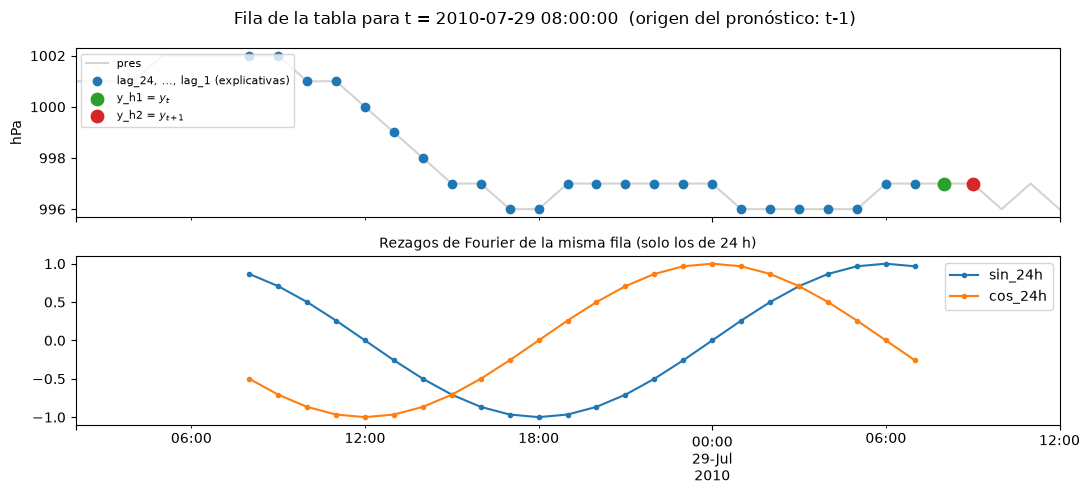

In [13]:
fecha_obj = datos.index[5000]          # una fila cualquiera, a modo de ilustración
ventana_fechas = pd.date_range(end=fecha_obj - pd.Timedelta(hours=1), periods=VENTANA, freq="h")

fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
pres[fecha_obj - pd.Timedelta(hours=30):fecha_obj + pd.Timedelta(hours=4)].plot(ax=ax[0], color="lightgray")
ax[0].scatter(ventana_fechas, pres[ventana_fechas], color="tab:blue", zorder=3, label="lag_24, …, lag_1 (explicativas)")
ax[0].scatter([fecha_obj], [pres[fecha_obj]], color="tab:green", s=80, zorder=3, label="y_h1 = $y_t$")
ax[0].scatter([fecha_obj + pd.Timedelta(hours=1)], [pres[fecha_obj + pd.Timedelta(hours=1)]], color="tab:red", s=80, zorder=3,
              label="y_h2 = $y_{t+1}$")
ax[0].set_ylabel("hPa"); ax[0].legend(fontsize=8, loc="upper left")
limites_x = ax[0].get_xlim()                              # pandas recorta el eje compartido al graficar el panel de abajo
fourier.loc[ventana_fechas, ["sin_24h", "cos_24h"]].plot(ax=ax[1], marker=".")
ax[0].set_xlim(limites_x)
ax[1].set_title("Rezagos de Fourier de la misma fila (solo los de 24 h)", fontsize=10)
fig.suptitle(f"Fila de la tabla para t = {fecha_obj}  (origen del pronóstico: t-1)")
plt.tight_layout(); plt.show()


> **Nota.** Como las variables de Fourier son determinísticas, también podríamos usar su valor en la hora que se pronostica ($t$ o $t+1$), no solo sus rezagos. En esta clase usamos únicamente rezagos; el ejercicio 3 propone la alternativa.

> ✏️ **Ejercicio 3.** (a) Encapsule la construcción anterior en una función `crear_tabla(serie, fourier, ventana)` y verifique con `np.allclose` que reproduce `datos`. (b) Agregue como variables explicativas las seis variables de Fourier **en la hora $t$** (la que se pronostica). ¿Por qué no hay fuga de información (*data leakage*) al hacerlo?

# 4. División temporal y estandarización

## 4.1 Entrenamiento, validación y prueba

En series de tiempo **no se barajan los datos**: se entrena con el pasado y se evalúa con el futuro.

| Conjunto | Proporción | Uso |
|---|---|---|
| Entrenamiento | 70% | Ajustar los pesos de las redes |
| Validación | 15% | Parada temprana y elección de hiperparámetros |
| Prueba | 15% | Evaluar **una sola vez** el modelo final |

In [15]:
n = len(datos)
n_train = int(n * 0.70)
n_val = int(n * 0.15)
n_test = n - n_train - n_val
print(f"Total {n}  =  entrenamiento {n_train}  +  validación {n_val}  +  prueba {n_test}")

i_train = slice(0, n_train)
i_val = slice(n_train, n_train + n_val)
i_test = slice(n_train + n_val, n)
for nombre, i in [("entrenamiento", i_train), ("validación", i_val), ("prueba", i_test)]:
    print(f"{nombre:>14}: {datos.index[i][0]}  a  {datos.index[i][-1]}")

Total 43799  =  entrenamiento 30659  +  validación 6569  +  prueba 6571
 entrenamiento: 2010-01-02 00:00:00  a  2013-07-02 10:00:00
    validación: 2013-07-02 11:00:00  a  2014-04-02 03:00:00
        prueba: 2014-04-02 04:00:00  a  2014-12-31 22:00:00


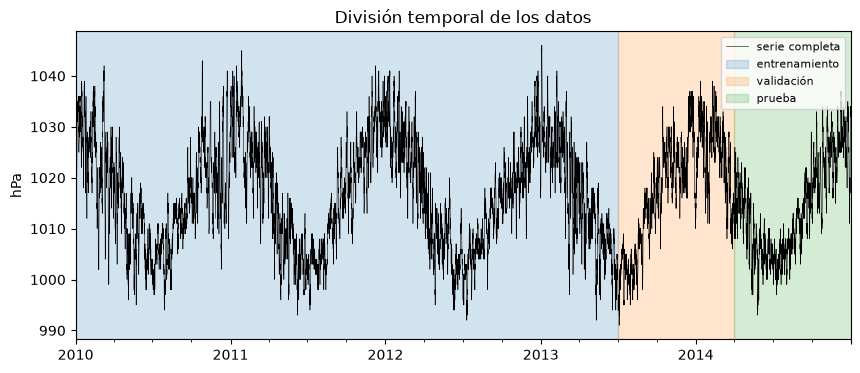

In [16]:
ax = pres.plot(color="black", lw=0.4, label="serie completa")
for i, color, nombre in [(i_train, "tab:blue", "entrenamiento"), (i_val, "tab:orange", "validación"), (i_test, "tab:green", "prueba")]:
    ax.axvspan(datos.index[i][0], datos.index[i][-1], color=color, alpha=0.2, label=nombre)
ax.set_title("División temporal de los datos"); ax.set_ylabel("hPa"); ax.legend(loc="upper right", fontsize=8)
plt.show()

## 4.2 Estandarización

Las redes neuronales se entrenan mejor cuando todas las entradas tienen escalas parecidas. La presión vale alrededor de 1016 hPa, mientras que las variables de Fourier están entre −1 y 1. Por eso **estandarizamos la presión**:

$$z = \frac{y - \bar y_{\text{entrenamiento}}}{s_{\text{entrenamiento}}}.$$

- La media y la desviación estándar se calculan **solo con el entrenamiento**, para no usar información del futuro.
- Se aplica la **misma transformación** a los rezagos (`lag_k`) y a las respuestas (`y_h1`, `y_h2`). Así una predicción puede reutilizarse como rezago en el pronóstico recursivo (sección 8).
- Las variables de Fourier **no se transforman**.
- Las métricas siempre se calculan en hPa, después de deshacer la transformación con `a_hpa`.

In [17]:
MEDIA = datos["y_h1"].iloc[i_train].mean()
DE = datos["y_h1"].iloc[i_train].std()
print(f"Media de entrenamiento: {MEDIA:.3f} hPa  |  desviación estándar: {DE:.3f} hPa")

def a_hpa(z):
    # Deshace la estandarización: de unidades z a hPa.
    return np.asarray(z) * DE + MEDIA

cols_presion = [c for c in datos.columns if c.startswith("lag_") or c.startswith("y_h")]
datos_z = datos.copy()
datos_z[cols_presion] = (datos[cols_presion] - MEDIA) / DE

# Matrices para keras (float32)
X_todo = datos_z[X_COLS].to_numpy("float32")                 # (n, 168)
Y_todo = datos_z[["y_h1", "y_h2"]].to_numpy("float32")       # (n, 2): respuestas a 1 y 2 pasos
X_train, X_val, X_test = X_todo[i_train], X_todo[i_val], X_todo[i_test]
Y_train, Y_val, Y_test = Y_todo[i_train], Y_todo[i_val], Y_todo[i_test]
X_train_val = np.concatenate([X_train, X_val])
Y_train_val = np.concatenate([Y_train, Y_val])

# Valores reales en hPa, para evaluar
y_val_h1, y_val_h2 = datos["y_h1"].iloc[i_val], datos["y_h2"].iloc[i_val]
y_test_h1, y_test_h2 = datos["y_h1"].iloc[i_test], datos["y_h2"].iloc[i_test]
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape)

Media de entrenamiento: 1016.582 hPa  |  desviación estándar: 10.369 hPa
X_train: (30659, 168) | Y_train: (30659, 2)


## 4.3 Errores a 1 y 2 pasos adelante

En todo el cuaderno reportamos el error de cada modelo **a 1 paso** ($y_t$, columna `y_h1`) y **a 2 pasos** ($y_{t+1}$, columna `y_h2`), siempre desde el mismo origen $t-1$. Cada tabla indica en su encabezado si el error se calcula en **validación** o en **prueba**.

Las redes de las secciones 6 y 7 se entrenan y se eligen para pronosticar 1 paso. Para obtener su pronóstico a 2 pasos usamos la **estrategia recursiva**, que no requiere entrenar otra red:

1. Se pronostica $\hat y_t$ con la ventana de las horas $t-24, \dots, t-1$.
2. Se desliza la ventana una hora: se quita la hora $t-24$ y se agrega la hora $t$, con la presión **pronosticada** $\hat y_t$ y las variables de Fourier de la hora $t$, que se conocen exactamente porque son determinísticas.
3. Con esa ventana se pronostica $\hat y_{t+1}$.

**¿Dónde se usa?** En todas las tablas de error de las secciones 6.2, 6.3, 6.6, 7.2, 7.5 y 10.1. En el código aparece como `pronostico_recursivo(...)`, y el encabezado de esas tablas dice "2 pasos con estrategia recursiva". La persistencia también es un pronóstico recursivo: pronostica $\hat y_t = y_{t-1}$ y, al repetir la regla, $\hat y_{t+1} = \hat y_t = y_{t-1}$.

En la sección 8 compararemos esta estrategia con otras dos (directa y *one-shot*).

In [18]:
F_t = fourier.loc[datos.index].to_numpy("float32")          # Fourier en la hora t de cada fila (la hora del paso 1)

def ventana_siguiente(W, y_nuevo_z, F_nuevo):
    # Desliza la ventana una hora: quita el paso más antiguo y agrega [y_nuevo, Fourier] como paso más reciente.
    paso_nuevo = np.column_stack([y_nuevo_z, F_nuevo])[:, None, :]
    return np.concatenate([W[:, 1:, :], paso_nuevo], axis=1).astype("float32")

def pronostico_recursivo(modelo, X, F_t, es_lstm):
    # Pronósticos a 1 y 2 pasos (en hPa) con un modelo de 1 paso. X puede ser la tabla (n, 168) o las ventanas (n, 24, 7).
    W = X.reshape(len(X), VENTANA, N_VARS)
    entrada = (lambda W: W) if es_lstm else (lambda W: W.reshape(len(W), -1))   # el MLP recibe la ventana aplanada
    p1 = modelo.predict(entrada(W), verbose=0).ravel()
    p2 = modelo.predict(entrada(ventana_siguiente(W, p1, F_t)), verbose=0).ravel()
    return a_hpa(p1), a_hpa(p2)

def evaluar_2pasos(y_h1, y_h2, p1, p2):
    # RECM y EAM (hPa) a 1 paso (y_t) y a 2 pasos (y_t+1), desde el mismo origen t-1.
    m1, m2 = evaluar(y_h1, p1), evaluar(y_h2, p2)
    return {"RECM 1 paso": m1["RECM"], "RECM 2 pasos": m2["RECM"], "EAM 1 paso": m1["EAM"], "EAM 2 pasos": m2["EAM"]}

def tabla_metricas(filas, conjunto, estrategia="recursiva"):
    # filas: {modelo: evaluar_2pasos(...)}. El conjunto (validación o prueba) y la estrategia usada
    # para los 2 pasos quedan en el encabezado de la tabla.
    tabla = pd.DataFrame(filas).T
    tabla.columns.name = f"{conjunto} (hPa), 2 pasos con estrategia {estrategia}" if estrategia else f"{conjunto} (hPa)"
    return tabla

# 5. Modelo de referencia: persistencia

Antes de entrenar redes necesitamos saber **qué tan difícil es el problema**. La referencia más simple es la **persistencia (modelo ingenuo)**: "la presión seguirá igual que en la última hora observada". Pronostica `lag_1` tanto para 1 como para 2 pasos adelante: desde el mismo origen $t-1$, $\hat y_t = \hat y_{t+1} = y_{t-1}$.

Por ahora la evaluamos en el conjunto de **validación**, donde compararemos los modelos mientras los elegimos. En prueba solo se evalúan los modelos finales (secciones 6.6, 7.5 y 8).

En la sección 6.2 agregaremos una segunda referencia: un **MLP con activaciones lineales**.

In [19]:
# Persistencia: desde el origen t-1 el pronóstico es lag_1 = y_(t-1), el mismo para los dos horizontes
pred_persistencia_val = datos["lag_1"].iloc[i_val]
referencias_val = {"persistencia": evaluar_2pasos(y_val_h1, y_val_h2, pred_persistencia_val, pred_persistencia_val)}
tabla_metricas(referencias_val, "validación").round(4)

"validación (hPa), 2 pasos con estrategia recursiva",RECM 1 paso,RECM 2 pasos,EAM 1 paso,EAM 2 pasos
persistencia,0.6887,1.0848,0.4278,0.7779


**¿Qué observamos?**

- En validación, a 1 paso la persistencia ya es un pronóstico **muy bueno** (RECM ≈ 0.69 hPa): la presión cambia en promedio menos de 1 hPa por hora.
- A 2 pasos el error crece a RECM ≈ 1.08 hPa (+58%). El pronóstico es el mismo valor $y_{t-1}$, pero se compara con otro valor real: el error a 1 paso es $y_t - y_{t-1}$ (el cambio en una hora) y el error a 2 pasos es $y_{t+1} - y_{t-1} = (y_t - y_{t-1}) + (y_{t+1} - y_t)$ (el cambio acumulado en dos horas). Si los cambios horarios fueran independientes, la RECM crecería en un factor $\sqrt{2} \approx 1.41$; crece más (1.58) porque cambios consecutivos tienden a tener el mismo signo.
- Además, como los datos están redondeados a 1 hPa, hay un error que **ningún modelo puede eliminar**: el redondeo por sí solo produce una RECM de aproximadamente $1/\sqrt{12} \approx 0.29$ hPa.
- Toda red debe superar a la persistencia; si no lo hace, no vale la pena.

# 6. Perceptrón multicapa (MLP)

## 6.1 ¿Qué es un MLP?

Un MLP con una capa oculta de $m$ neuronas calcula

$$\hat y = \mathbf{w}_2^\top \, \varphi\!\left(\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1\right) + b_2,$$

donde $\mathbf{x}$ son las 168 variables explicativas, $\varphi$ es una **función de activación** no lineal (por ejemplo `relu` o `tanh`) y los pesos $\mathbf{W}_1, \mathbf{b}_1, \mathbf{w}_2, b_2$ se estiman minimizando el error cuadrático medio con el optimizador **Adam**. Con más capas ocultas se repite la operación $\varphi(\mathbf{W}\cdot + \mathbf{b})$.

**Hiperparámetros** (se eligen, no se estiman): número de capas, neuronas por capa, activación, tasa de aprendizaje y número de épocas.

**Parada temprana (*early stopping*).** En cada época se calcula el error en validación. Si no mejora durante `paciencia` épocas, el entrenamiento se detiene y se recuperan los pesos de la **mejor época**. Así el número de épocas se elige con la validación.

Definimos funciones auxiliares que usaremos en todo el cuaderno:

In [20]:
EPOCAS_MAX = 100
LOTE = 128          # tamaño del lote (batch_size)

def crear_mlp(capas=(8,), activacion="relu", tasa=1e-3, n_salidas=1): #crear_mlp(capas=(32, 16, 8))   # 3 capas ocultas
    # MLP con las capas ocultas indicadas; n_salidas=2 se usa en la estrategia one-shot (sección 8).
    keras.utils.set_random_seed(SEMILLA)                      # misma inicialización cada vez: resultados reproducibles
    modelo = keras.Sequential([keras.Input(shape=(VENTANA * N_VARS,))])
    for unidades in capas:
        modelo.add(keras.layers.Dense(unidades, activation=activacion))
    modelo.add(keras.layers.Dense(n_salidas))                 # salida lineal
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss="mse")
    return modelo

def parada_temprana(paciencia=5):
    return keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True)

def entrenar_con_validacion(modelo, X_tr, y_tr, X_va, y_va, paciencia=5):
    # Entrena con parada temprana y devuelve la historia (ECM por época) como DataFrame.
    historia = modelo.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCAS_MAX, batch_size=LOTE,
                          callbacks=[parada_temprana(paciencia)], verbose=0)
    historia = pd.DataFrame(historia.history)
    historia.index = historia.index + 1
    historia.index.name = "época"
    return historia

def graficar_historia(historia, titulo):
    recm = np.sqrt(historia[["loss", "val_loss"]]) * DE                 # de ECM en unidades z a RECM en hPa
    ax = recm.rename(columns={"loss": "entrenamiento", "val_loss": "validación"}).plot(marker=".")
    ax.axvline(historia["val_loss"].idxmin(), color="red", ls="--", label=f"mejor época = {historia['val_loss'].idxmin()}")
    ax.set_ylabel("RECM a 1 paso (hPa)"); ax.set_title(titulo); ax.legend(); plt.show()

## 6.2 Referencia: MLP con activaciones lineales

Antes de usar activaciones no lineales entrenamos una red con **una capa oculta de 64 neuronas y activación lineal**, $\varphi(u) = u$. Al sustituir en la fórmula de la sección 6.1:

$$\hat y = \mathbf{w}_2^\top\left(\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1\right) + b_2
= \underbrace{\left(\mathbf{W}_1^\top \mathbf{w}_2\right)^\top}_{\boldsymbol\beta^\top} \mathbf{x} + \underbrace{\mathbf{w}_2^\top \mathbf{b}_1 + b_2}_{\beta_0}.$$

La red tiene $168 \times 64 + 64 + 64 + 1 = 10\,881$ parámetros, pero la función que calcula es **lineal en las variables explicativas**: un vector $\boldsymbol\beta$ de 168 coeficientes y un intercepto $\beta_0$. Agregar más capas lineales tampoco cambia esto, porque una composición de funciones lineales sigue siendo lineal.

Por eso es la referencia natural para el resto de la sección: **un MLP con activaciones no lineales solo vale la pena si supera al MLP lineal.** Si no lo supera, la no linealidad no está aportando.

In [21]:
mlp_lineal = crear_mlp(capas=(64,), activacion="linear")
mlp_lineal.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        10,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,881 (42.50 KB)

 Trainable params: 10,881 (42.50 KB)

 Non-trainable params: 0 (0.00 B)

**Paciencia de 20 épocas.** La curva de validación de esta red es irregular en las primeras épocas: baja, sube y vuelve a bajar. Con la paciencia de 5 épocas que usan las demás redes, el entrenamiento se detiene alrededor de la época 7, mucho antes de que la red termine de aprender. Por eso aquí usamos `paciencia=20`.

**Errores a 1 y 2 pasos.** La tabla de abajo agrega el MLP lineal a la de la persistencia. El error a 2 pasos se obtiene con la **estrategia recursiva** (sección 4.3): la red pronostica $\hat y_t$, ese valor entra como `lag_1` en la ventana desplazada una hora, y la misma red pronostica $\hat y_{t+1}$.

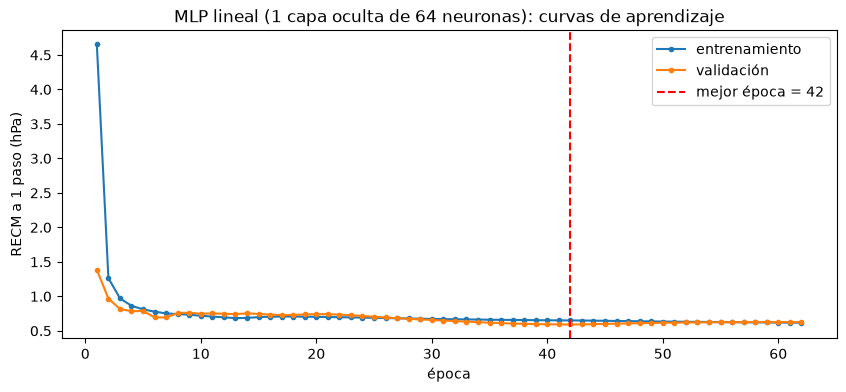

"validación (hPa), 2 pasos con estrategia recursiva",RECM 1 paso,RECM 2 pasos,EAM 1 paso,EAM 2 pasos
persistencia,0.6887,1.0848,0.4278,0.7779
MLP lineal 1x64,0.5917,0.8418,0.4693,0.6665


In [22]:
historia_mlp_lineal = entrenar_con_validacion(mlp_lineal, X_train, Y_train[:, 0], X_val, Y_val[:, 0], paciencia=20)
EPOCAS_MLP_LINEAL = int(historia_mlp_lineal["val_loss"].idxmin())
graficar_historia(historia_mlp_lineal, "MLP lineal (1 capa oculta de 64 neuronas): curvas de aprendizaje")

# 1 paso: la red aplicada a la ventana. 2 pasos: estrategia recursiva (sección 4.3)
referencias_val["MLP lineal 1x64"] = evaluar_2pasos(y_val_h1, y_val_h2, *pronostico_recursivo(mlp_lineal, X_val, F_t[i_val], es_lstm=False))
tabla_metricas(referencias_val, "validación").round(4)

**Verificación.** Con los pesos estimados calculamos $\boldsymbol\beta = \mathbf{W}_1 \mathbf{w}_2$ y $\beta_0 = \mathbf{b}_1^\top \mathbf{w}_2 + b_2$, y comprobamos que la red predice exactamente $\mathbf{x}^\top \boldsymbol\beta + \beta_0$.

In [23]:
W1, b1 = mlp_lineal.layers[0].get_weights()          # (168, 64) y (64,)
w2, b2 = mlp_lineal.layers[1].get_weights()          # (64, 1) y (1,)
beta = W1 @ w2                                       # (168, 1): un coeficiente por variable explicativa
beta0 = b1 @ w2 + b2

print("Número de coeficientes efectivos:", beta.size, "+ intercepto")
print("Predicción de la red = X·β + β0:",
      np.allclose(mlp_lineal.predict(X_val, verbose=0), X_val @ beta + beta0, atol=1e-4))

# Los coeficientes más grandes (en unidades z): ¿qué rezagos usa el modelo lineal?
pd.Series(beta.ravel(), index=X_COLS).sort_values(key=np.abs, ascending=False).head(8).round(3)

Número de coeficientes efectivos: 168 + intercepto
Predicción de la red = X·β + β0: True


lag_1               0.899
cos_12h_lag_20     -0.246
lag_2               0.237
sin_24h_lag_17      0.206
cos_12h_lag_15      0.195
cos_anual_lag_5    -0.165
cos_anual_lag_20    0.164
sin_12h_lag_7      -0.150
dtype: float32

**¿Qué observamos?**

- El MLP lineal mejora a la persistencia en validación en los dos horizontes: a 1 paso, RECM ≈ 0.592 frente a ≈ 0.689 hPa; a 2 pasos, ≈ 0.842 frente a ≈ 1.085. Combinar linealmente las 24 horas de la ventana y las variables de Fourier ya aporta información.
- **Los coeficientes efectivos son interpretables**, como en un modelo autorregresivo. El mayor es el de `lag_1` (≈ 0.9): la hora anterior domina, como mostró la PACF. El de `lag_2` es mucho menor (≈ 0.24), y entre los más grandes aparecen varios rezagos de las variables de Fourier de 12 h, 24 h y anual. Así se representan los ciclos. **Cuidado al interpretar estos últimos:** como los rezagos de Fourier son perfectamente colineales (sección 3), sus coeficientes individuales no están identificados, porque muchas combinaciones distintas dan la misma predicción. Lo interpretable es su efecto conjunto: una onda $a\,s_t + b\,c_t$ por cada periodo.
- **Este es el modelo que deben superar los MLP con activaciones no lineales.**

## 6.3 Paso 1: un MLP elemental

Antes de buscar hiperparámetros entrenamos un modelo **muy sencillo**: una capa oculta con 8 neuronas `relu` y tasa de aprendizaje 0.001. Sirve para comprobar que todo funciona y para tener un punto de partida.

In [24]:
mlp_elemental = crear_mlp(capas=(8,))
mlp_elemental.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 8)              │         1,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,361 (5.32 KB)

 Trainable params: 1,361 (5.32 KB)

 Non-trainable params: 0 (0.00 B)

**Número de parámetros:** la capa oculta tiene $168 \times 8 + 8 = 1352$ pesos y la de salida $8 + 1 = 9$.

Como en la sección 6.2, el error a 2 pasos se obtiene con la estrategia recursiva: el MLP elemental se aplica dos veces, la segunda con su propio pronóstico $\hat y_t$ como `lag_1`.

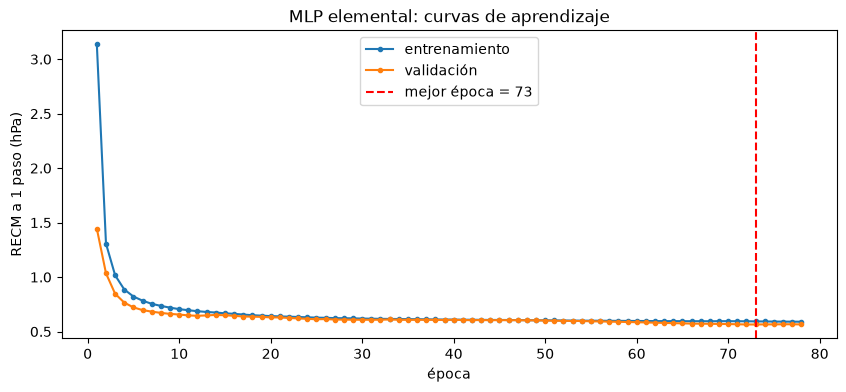

"validación (hPa), 2 pasos con estrategia recursiva",RECM 1 paso,RECM 2 pasos,EAM 1 paso,EAM 2 pasos
persistencia,0.6887,1.0848,0.4278,0.7779
MLP lineal 1x64,0.5917,0.8418,0.4693,0.6665
MLP elemental,0.5650,0.7774,0.4450,0.6113


In [25]:
historia_mlp_elemental = entrenar_con_validacion(mlp_elemental, X_train, Y_train[:, 0], X_val, Y_val[:, 0])
EPOCAS_MLP_ELEMENTAL = historia_mlp_elemental["val_loss"].idxmin()
graficar_historia(historia_mlp_elemental, "MLP elemental: curvas de aprendizaje")

pred_val_mlp_elemental = pronostico_recursivo(mlp_elemental, X_val, F_t[i_val], es_lstm=False)     # (1 paso, 2 pasos recursivo) en hPa
tabla_metricas({**referencias_val, "MLP elemental": evaluar_2pasos(y_val_h1, y_val_h2, *pred_val_mlp_elemental)}, "validación").round(4)

**¿Qué observamos?**

- Las curvas bajan rápido en las primeras épocas y luego se estabilizan. La parada temprana se queda con la época de menor error en validación (línea roja).
- Con solo 8 neuronas `relu` (1361 parámetros, frente a 10 881 del MLP lineal), el MLP elemental **supera al MLP lineal** en validación en los dos horizontes: a 1 paso, RECM ≈ 0.565 frente a ≈ 0.592; a 2 pasos, ≈ 0.777 frente a ≈ 0.842. La no linealidad parece aportar algo.
- Es solo un punto de partida. La pregunta es si otros hiperparámetros ayudan.

## 6.4 Paso 2: búsqueda de hiperparámetros con el conjunto de validación

Usamos `keras_tuner.GridSearch`, que entrena **todas** las combinaciones de la malla y conserva la de menor error de validación (`val_loss`). Cada combinación se entrena con parada temprana.

| Hiperparámetro | Valores |
|---|---|
| Número de capas ocultas | 1, 2 |
| Neuronas por capa | 16, 64 |
| Activación | `relu`, `tanh` |
| Tasa de aprendizaje | 0.001, 0.01 |

En total $2 \times 2 \times 2 \times 2 = 16$ combinaciones.

In [26]:
def construir_mlp(hp):
    n_capas = hp.Choice("n_capas", [1, 2])
    unidades = hp.Choice("unidades", [16, 64])
    activacion = hp.Choice("activacion", ["relu", "tanh"])
    tasa = hp.Choice("tasa", [1e-3, 1e-2])
    return crear_mlp(capas=(unidades,) * n_capas, activacion=activacion, tasa=tasa)

buscador_mlp = kt.GridSearch(construir_mlp, objective="val_loss", seed=SEMILLA, overwrite=True,
                             directory="busqueda_hiperparametros", project_name="mlp")
buscador_mlp.search_space_summary()

Search space summary
Default search space size: 4
n_capas (Choice)
{'default': 1, 'conditions': [], 'values': [1, 2], 'ordered': True}
unidades (Choice)
{'default': 16, 'conditions': [], 'values': [16, 64], 'ordered': True}
activacion (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
tasa (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.01], 'ordered': True}


In [27]:
buscador_mlp.search(X_train, Y_train[:, 0], validation_data=(X_val, Y_val[:, 0]), epochs=EPOCAS_MAX, batch_size=LOTE,
                    callbacks=[parada_temprana(3)], verbose=0)

In [28]:
def tabla_busqueda(buscador):
    # Resume la búsqueda: una fila por combinación, con la RECM de validación a 1 paso en hPa (de menor a mayor).
    filas = []
    for ensayo in buscador.oracle.get_best_trials(num_trials=1000):
        hp = {k: v for k, v in ensayo.hyperparameters.values.items() if not k.startswith("tuner/")}
        filas.append({**hp, "RECM validación 1 paso": np.sqrt(ensayo.score) * DE})
    tabla = pd.DataFrame(filas)
    # Hyperband puede evaluar la misma combinación más de una vez: se conserva su mejor resultado
    return tabla.drop_duplicates(subset=list(hp.keys()), keep="first").reset_index(drop=True)

resultados_mlp = tabla_busqueda(buscador_mlp)
resultados_mlp.round(4)

,n_capas,unidades,activacion,tasa,RECM validación 1 paso
0,2,16,relu,0.001,0.5500
1,2,64,tanh,0.001,0.5628
2,1,64,tanh,0.001,0.5903
3,2,64,relu,0.001,0.5950
4,1,64,relu,0.010,0.6034
5,1,16,tanh,0.001,0.6066
6,2,16,relu,0.010,0.6397
7,2,16,tanh,0.001,0.6400
8,1,16,tanh,0.010,0.6451
9,1,64,relu,0.001,0.6500


**¿Qué observamos?**

- La mejor combinación (2 capas de 64 neuronas `tanh`, tasa 0.001 o 2 capas y 16 unidades) tiene una RECM de validación a 1 paso ≈ 0.563 hPa. Es apenas mejor que el MLP elemental (≈ 0.565) y mejor que el MLP lineal (≈ 0.592).
- La búsqueda optimiza solo el error a 1 paso, porque es la tarea para la que se entrena la red.
- La tasa de aprendizaje 0.01 es peor en 7 de las 8 combinaciones: con pasos grandes, el optimizador oscila alrededor del mínimo en lugar de acercarse a él.
- Más neuronas no garantiza un mejor resultado: hay combinaciones de 16 y de 64 neuronas tanto arriba como abajo de la tabla.
- Muchas combinaciones tienen errores muy parecidos. Con **un solo bloque** de validación, esas diferencias pueden deberse al azar o a la época del año del bloque. Eso lo revisamos con la validación cruzada.

## 6.5 Paso 3: validación cruzada secuencial

La búsqueda anterior usó **un solo bloque** de validación. Como en la clase de árboles, la elección puede depender de la época del año que cae en ese bloque. La **validación cruzada secuencial** evalúa cada candidato en varios bloques consecutivos **dentro del entrenamiento**, con una ventana de entrenamiento que crece:

- 4 pliegues de 3000 horas (unos 4 meses cada uno).
- En cada pliegue se entrena con todo lo anterior y se valida con el bloque siguiente.

**Candidatos:** el MLP elemental y las 3 mejores combinaciones de la búsqueda.

**¿Y el número de épocas?** Dentro de la validación cruzada no hay un conjunto aparte para la parada temprana. Por eso, para cada candidato, primero entrenamos con entrenamiento/validación para encontrar su **mejor época**, y en los pliegues entrenamos **exactamente ese número de épocas**. El número de épocas se trata como un hiperparámetro más.

In [29]:
N_PLIEGUES, TAM_PLIEGUE = 4, 3000
cv_secuencial = TimeSeriesSplit(n_splits=N_PLIEGUES, test_size=TAM_PLIEGUE)
pliegues = list(cv_secuencial.split(X_train))
fechas_train = datos.index[i_train]

pd.DataFrame([{"pliegue": k + 1,
               "filas entrenamiento": len(i_tr),
               "entrena hasta": fechas_train[i_tr[-1]],
               "valida desde": fechas_train[i_va[0]],
               "valida hasta": fechas_train[i_va[-1]]}
              for k, (i_tr, i_va) in enumerate(pliegues)]).set_index("pliegue")

,filas entrenamiento,entrena hasta,valida desde,valida hasta
pliegue,,,,
1,18659,2012-02-18 10:00:00,2012-02-18 11:00:00,2012-06-22 10:00:00
2,21659,2012-06-22 10:00:00,2012-06-22 11:00:00,2012-10-25 10:00:00
3,24659,2012-10-25 10:00:00,2012-10-25 11:00:00,2013-02-27 10:00:00
4,27659,2013-02-27 10:00:00,2013-02-27 11:00:00,2013-07-02 10:00:00


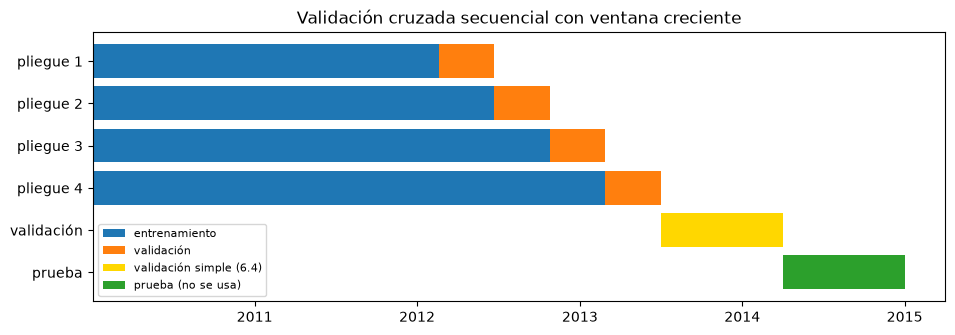

In [30]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for k, (i_tr, i_va) in enumerate(pliegues):
    fila = N_PLIEGUES - k + 1
    ax.barh(fila, fechas_train[i_tr[-1]] - fechas_train[i_tr[0]], left=fechas_train[i_tr[0]], color="tab:blue",
            label="entrenamiento" if k == 0 else None)
    ax.barh(fila, fechas_train[i_va[-1]] - fechas_train[i_va[0]], left=fechas_train[i_va[0]], color="tab:orange",
            label="validación" if k == 0 else None)
ax.barh(1, datos.index[i_val][-1] - datos.index[i_val][0], left=datos.index[i_val][0], color="gold",
        label="validación simple (6.4)")
ax.barh(0, datos.index[i_test][-1] - datos.index[i_test][0], left=datos.index[i_test][0], color="tab:green",
        label="prueba (no se usa)")
ax.set_yticks(range(N_PLIEGUES + 2), ["prueba", "validación"] + [f"pliegue {N_PLIEGUES - j}" for j in range(N_PLIEGUES)])
ax.set_title("Validación cruzada secuencial con ventana creciente")
ax.legend(loc="lower left", fontsize=8); plt.show()

Función genérica para la validación cruzada: recibe una función que **ajusta con unos datos y predice otros**, y devuelve la RECM a 1 paso (hPa) en cada pliegue. Así sirve para la persistencia, el MLP lineal, el MLP y la LSTM. La RECM de la validación cruzada se calcula promediando los ECM de los pliegues (todos tienen el mismo tamaño) y sacando la raíz, igual que en la clase de árboles.

In [31]:
def recm_pliegues(ajustar_y_predecir, X, y):
    recm = []
    for i_tr, i_va in pliegues:
        pred = ajustar_y_predecir(X[i_tr], y[i_tr], X[i_va])
        recm.append(root_mean_squared_error(a_hpa(y[i_va]), a_hpa(pred)))
    return recm

def red_con_epocas(crear, epocas):
    # Ajusta una red nueva con un número fijo de épocas y predice.
    def ajustar_y_predecir(X_tr, y_tr, X_va):
        modelo = crear()
        modelo.fit(X_tr, y_tr, epochs=epocas, batch_size=LOTE, verbose=0)
        return modelo.predict(X_va, verbose=0).ravel()
    return ajustar_y_predecir

def persistencia_z(X_tr, y_tr, X_va):
    return X_va[:, X_COLS.index("lag_1")]

def tabla_cv(resultados):
    # resultados: {nombre: {"pliegues": [...], otras columnas}} -> DataFrame ordenado por RECM_cv 1 paso
    filas = {}
    for nombre, r in resultados.items():
        fila = {f"pliegue {k + 1}": v for k, v in enumerate(r["pliegues"])}
        fila["RECM_cv 1 paso"] = np.sqrt(np.mean(np.square(r["pliegues"])))
        fila.update({k: v for k, v in r.items() if k != "pliegues"})
        filas[nombre] = fila
    tabla = pd.DataFrame(filas).T.astype(float).sort_values("RECM_cv 1 paso")
    tabla.columns.name = "validación cruzada, 1 paso (hPa)"
    return tabla

cv_referencias = {"persistencia": {"pliegues": recm_pliegues(persistencia_z, X_train, Y_train[:, 0])},
                  "MLP lineal 1x64": {"pliegues": recm_pliegues(red_con_epocas(lambda: crear_mlp(capas=(64,), activacion="linear"),
                                                                              EPOCAS_MLP_LINEAL), X_train, Y_train[:, 0]),
                                      "épocas": EPOCAS_MLP_LINEAL}}
tabla_cv(cv_referencias).round(4)

"validación cruzada, 1 paso (hPa)",pliegue 1,pliegue 2,pliegue 3,pliegue 4,RECM_cv 1 paso,épocas
MLP lineal 1x64,0.6672,0.5660,0.5873,0.8004,0.6617,42.0
persistencia,0.7414,0.5925,0.7004,0.7576,0.7009,NaN


Ahora los candidatos MLP. Para cada uno: (1) mejor época con entrenamiento/validación; (2) validación cruzada con ese número de épocas.

In [32]:
def describir_mlp(hp):
    return f"MLP {int(hp['n_capas'])}x{int(hp['unidades'])} {hp['activacion']}, tasa={hp['tasa']}"

candidatos_mlp = {"MLP elemental 1x8 relu, tasa=0.001": dict(capas=(8,), activacion="relu", tasa=1e-3)}
for _, hp in resultados_mlp.head(3).iterrows():
    candidatos_mlp[describir_mlp(hp)] = dict(capas=(int(hp["unidades"]),) * int(hp["n_capas"]),
                                             activacion=hp["activacion"], tasa=hp["tasa"])

cv_mlp = {}
for nombre, config in candidatos_mlp.items():
    modelo = crear_mlp(**config)
    historia = entrenar_con_validacion(modelo, X_train, Y_train[:, 0], X_val, Y_val[:, 0])
    epocas = int(historia["val_loss"].idxmin())
    cv_mlp[nombre] = {"pliegues": recm_pliegues(red_con_epocas(lambda: crear_mlp(**config), epocas), X_train, Y_train[:, 0]),
                      "RECM validación 1 paso": np.sqrt(historia["val_loss"].min()) * DE,
                      "épocas": epocas}
    print(f"{nombre}: listo ({epocas} épocas)")

resultados_cv_mlp = tabla_cv({**cv_mlp, **cv_referencias})
resultados_cv_mlp.round(4)

MLP elemental 1x8 relu, tasa=0.001: listo (73 épocas)
MLP 2x16 relu, tasa=0.001: listo (50 épocas)
MLP 2x64 tanh, tasa=0.001: listo (26 épocas)
MLP 1x64 tanh, tasa=0.001: listo (20 épocas)


"validación cruzada, 1 paso (hPa)",pliegue 1,pliegue 2,pliegue 3,pliegue 4,RECM_cv 1 paso,RECM validación 1 paso,épocas
"MLP 2x16 relu, tasa=0.001",0.6889,0.5411,0.5867,0.6342,0.6152,0.5500,50.0
"MLP elemental 1x8 relu, tasa=0.001",0.6943,0.5861,0.5593,0.6425,0.6227,0.5650,73.0
"MLP 2x64 tanh, tasa=0.001",0.6396,0.5991,0.6098,0.6646,0.6288,0.5628,26.0
"MLP 1x64 tanh, tasa=0.001",0.6770,0.6148,0.5751,0.6467,0.6295,0.5861,20.0
MLP lineal 1x64,0.6672,0.5660,0.5873,0.8004,0.6617,NaN,42.0
persistencia,0.7414,0.5925,0.7004,0.7576,0.7009,NaN,NaN


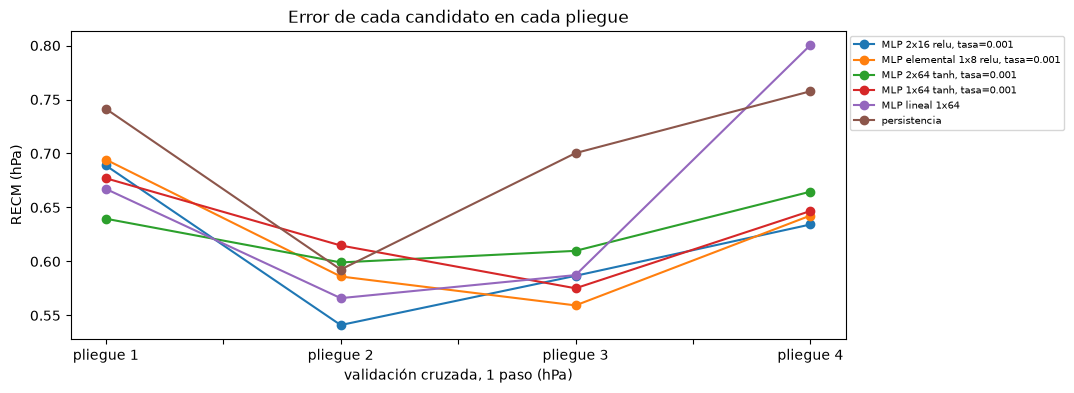

In [33]:
ax = resultados_cv_mlp.filter(like="pliegue").T.plot(marker="o", figsize=(10, 4))
ax.set_ylabel("RECM (hPa)"); ax.set_title("Error de cada candidato en cada pliegue")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1)); plt.show()

In [34]:
nombre_mlp = resultados_cv_mlp.drop(index=list(cv_referencias)).index[0]
CONFIG_MLP = candidatos_mlp[nombre_mlp]
EPOCAS_MLP = int(resultados_cv_mlp.loc[nombre_mlp, "épocas"])
print("MLP elegido por validación cruzada:", nombre_mlp, "|", EPOCAS_MLP, "épocas")
print("MLP elegido por validación simple: ", resultados_cv_mlp.drop(index=list(cv_referencias))["RECM validación 1 paso"].astype(float).idxmin())

MLP elegido por validación cruzada: MLP 2x16 relu, tasa=0.001 | 50 épocas
MLP elegido por validación simple:  MLP 2x16 relu, tasa=0.001


**¿Qué aprendimos?**

1. **Los dos criterios eligen modelos distintos.** La validación simple elige el MLP 2×64 `tanh` (RECM de validación a 1 paso ≈ 0.563). La validación cruzada elige el **MLP elemental** (RECM_cv a 1 paso ≈ 0.623, frente a ≈ 0.629 del 2×64 `tanh`). Un solo bloque de validación puede favorecer a un modelo que no es el mejor en otras épocas del año. Seguimos la validación cruzada, que promedia 4 bloques. El modelo elemental resultó ser el mejor candidato.
2. **Los cuatro MLP no lineales superan al MLP lineal en la validación cruzada** (RECM_cv a 1 paso entre ≈ 0.623 y ≈ 0.648, frente a ≈ 0.662). Pero las diferencias entre ellos son pequeñas.
3. **La validación simple fue optimista.** Todos los errores de validación simple a 1 paso (≈ 0.56–0.59) están por debajo de los de la validación cruzada (≈ 0.62–0.66), porque el bloque de validación fue más fácil de predecir que los pliegues.
4. **El error depende de la época del año.** Los pliegues 1 y 4 (febrero a junio/julio de 2012 y de 2013) son los más difíciles para todos los modelos, incluida la persistencia. Los pliegues 2 y 3 (junio de 2012 a febrero de 2013) son los más fáciles, sobre todo el 2 (junio a octubre): en verano la presión es más estable.
5. **El MLP lineal es el menos estable.** En el pliegue 4 es incluso peor que la persistencia (≈ 0.80 frente a ≈ 0.76), mientras que en el pliegue 2 es el mejor de todos (≈ 0.566).

> ✏️ **Ejercicio 4.** Repita la validación cruzada con una **ventana deslizante** de tamaño fijo: `TimeSeriesSplit(n_splits=4, test_size=3000, max_train_size=12000)`. ¿Cambia el candidato elegido? ¿Cuándo convendría una ventana deslizante?

## 6.6 Paso 4: modelo final y evaluación en prueba

Con la configuración y el número de épocas elegidos, **reentrenamos con entrenamiento + validación** y evaluamos **una sola vez** en prueba. El pronóstico a 2 pasos de cada red se obtiene con la estrategia recursiva (sección 4.3), aplicando dos veces el modelo final de 1 paso.

In [35]:
mlp_final = crear_mlp(**CONFIG_MLP)
mlp_final.fit(X_train_val, Y_train_val[:, 0], epochs=EPOCAS_MLP, batch_size=LOTE, verbose=0)
pred_test_mlp, pred_test_mlp_h2 = pronostico_recursivo(mlp_final, X_test, F_t[i_test], es_lstm=False)   # 1 paso y 2 pasos (recursivo), en hPa

mlp_lineal_final = crear_mlp(capas=(64,), activacion="linear")
mlp_lineal_final.fit(X_train_val, Y_train_val[:, 0], epochs=EPOCAS_MLP_LINEAL, batch_size=LOTE, verbose=0)
pred_test_lineal = pronostico_recursivo(mlp_lineal_final, X_test, F_t[i_test], es_lstm=False)

pred_test_persistencia = datos["lag_1"].iloc[i_test]
prueba = {"persistencia": evaluar_2pasos(y_test_h1, y_test_h2, pred_test_persistencia, pred_test_persistencia),
          "MLP lineal 1x64": evaluar_2pasos(y_test_h1, y_test_h2, *pred_test_lineal),
          f"MLP final ({nombre_mlp})": evaluar_2pasos(y_test_h1, y_test_h2, pred_test_mlp, pred_test_mlp_h2)}
tabla_metricas(prueba, "prueba").round(4)

"prueba (hPa), 2 pasos con estrategia recursiva",RECM 1 paso,RECM 2 pasos,EAM 1 paso,EAM 2 pasos
persistencia,0.6730,1.0503,0.4142,0.7524
MLP lineal 1x64,0.5592,0.7623,0.4431,0.5960
"MLP final (MLP 2x16 relu, tasa=0.001)",0.5580,0.7596,0.4362,0.5898


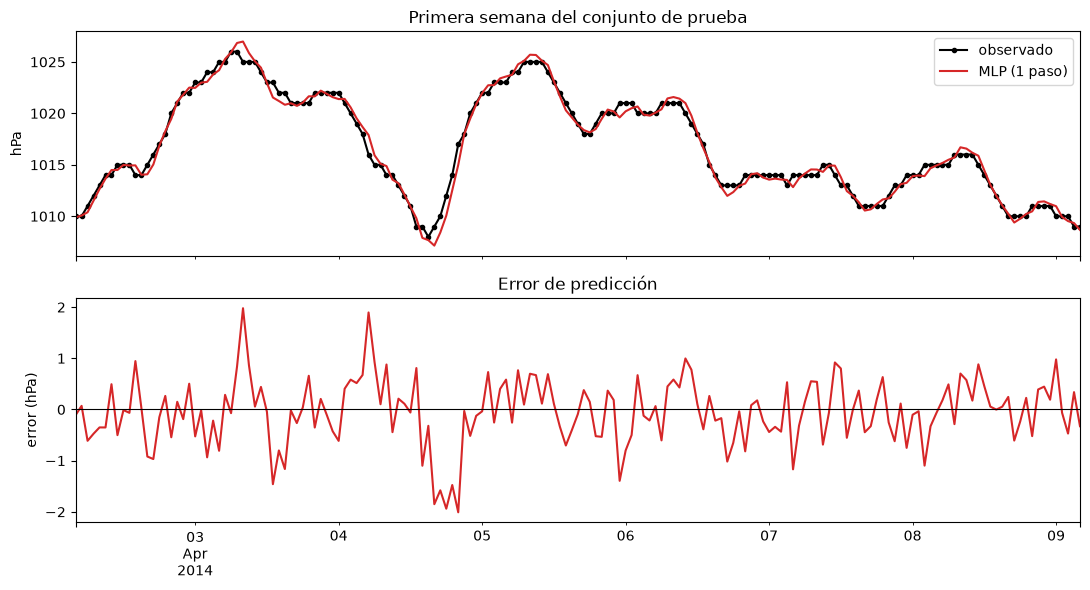

In [36]:
pred_test_mlp_s = pd.Series(pred_test_mlp, index=y_test_h1.index)
desde, hasta = y_test_h1.index[0], y_test_h1.index[0] + pd.Timedelta(days=7)

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
y_test_h1[desde:hasta].plot(ax=ax[0], color="black", marker=".", label="observado")
pred_test_mlp_s[desde:hasta].plot(ax=ax[0], color="tab:red", label="MLP (1 paso)")
ax[0].set_ylabel("hPa"); ax[0].set_title("Primera semana del conjunto de prueba"); ax[0].legend()
(pred_test_mlp_s - y_test_h1)[desde:hasta].plot(ax=ax[1], color="tab:red")
ax[1].axhline(0, color="black", lw=0.8); ax[1].set_ylabel("error (hPa)"); ax[1].set_title("Error de predicción")
plt.tight_layout(); plt.show()

> ✏️ **Ejercicio 5.** (a) Agregue una capa `keras.layers.Dropout(0.2)` después de cada capa oculta del MLP elegido. ¿Mejora la RECM en validación? (b) En lugar de pronosticar el nivel $y_t$, entrene el MLP para pronosticar el **cambio** $y_t - y_{t-1}$ y luego sume `lag_1`. Compare con el modelo de esta sección.

# 7. Red LSTM

## 7.1 De la tabla a las ventanas

Una red **LSTM** (*Long Short-Term Memory*) es una red recurrente: lee la ventana **hora por hora**, de la más antigua a la más reciente, y actualiza una memoria interna en cada paso. Por eso no recibe una fila plana de 168 números, sino un arreglo de forma

$$(\text{muestras},\ \text{pasos de tiempo} = 24,\ \text{variables por paso} = 7).$$

Como ordenamos las columnas por hora y dentro de cada hora siempre en el mismo orden (sección 3), basta con un `reshape`:

In [40]:
def a_ventanas(X):
    return X.reshape(len(X), VENTANA, N_VARS)

W_train, W_val, W_test = a_ventanas(X_train), a_ventanas(X_val), a_ventanas(X_test)
W_train_val = a_ventanas(X_train_val)
print("Forma de las ventanas de entrenamiento:", W_train.shape)

# Verificación: el último paso de la ventana es la hora t-1 y el primero la hora t-24
print("Último paso, presión = lag_1:  ", np.allclose(W_train[:, -1, 0], datos_z["lag_1"].iloc[i_train]))
print("Primer paso, presión = lag_24: ", np.allclose(W_train[:, 0, 0], datos_z["lag_24"].iloc[i_train]))
print("Último paso, cos_anual = cos_anual_lag_1:", np.allclose(W_train[:, -1, 6], datos_z["cos_anual_lag_1"].iloc[i_train]))

pd.DataFrame(W_train[0], columns=VARIABLES, index=[f"t-{k}" for k in LAGS]).round(3).tail(24)

Forma de las ventanas de entrenamiento: (30659, 24, 7)
Último paso, presión = lag_1:   True
Primer paso, presión = lag_24:  True
Último paso, cos_anual = cos_anual_lag_1: True


,pres,sin_24h,cos_24h,sin_12h,cos_12h,sin_anual,cos_anual
t-24,0.426,0.000,1.000,0.000,1.000,0.000,1.0
t-23,0.330,0.259,0.966,0.500,0.866,0.001,1.0
t-22,0.233,0.500,0.866,0.866,0.500,0.001,1.0
t-21,0.233,0.707,0.707,1.000,0.000,0.002,1.0
t-20,0.137,0.866,0.500,0.866,-0.500,0.003,1.0
t-19,0.040,0.966,0.259,0.500,-0.866,0.004,1.0
t-18,0.040,1.000,0.000,0.000,-1.000,0.004,1.0
t-17,0.040,0.966,-0.259,-0.500,-0.866,0.005,1.0
t-16,0.040,0.866,-0.500,-0.866,-0.500,0.006,1.0
t-15,0.040,0.707,-0.707,-1.000,-0.000,0.006,1.0


Cada fila de este último cuadro es **un paso de tiempo** de la primera ventana: la presión estandarizada y las seis variables de Fourier de esa hora.

Función auxiliar para crear LSTM. Con más de una capa, las capas intermedias deben devolver la secuencia completa (`return_sequences=True`) para que la siguiente capa LSTM la lea paso a paso; la última devuelve solo su estado final.

In [41]:
def crear_lstm(capas=(8,), tasa=1e-3, n_salidas=1):
    keras.utils.set_random_seed(SEMILLA)
    modelo = keras.Sequential([keras.Input(shape=(VENTANA, N_VARS))])
    for j, unidades in enumerate(capas):
        modelo.add(keras.layers.LSTM(unidades, return_sequences=(j < len(capas) - 1)))
    modelo.add(keras.layers.Dense(n_salidas))
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss="mse")
    return modelo

## 7.2 Paso 1: una LSTM elemental

Una sola capa LSTM con 8 unidades y tasa de aprendizaje 0.001 (activación `tanh`, la de defecto).

In [42]:
lstm_elemental = crear_lstm(capas=(8,))
lstm_elemental.summary()

Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 8)              │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_66 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 521 (2.04 KB)

 Trainable params: 521 (2.04 KB)

 Non-trainable params: 0 (0.00 B)

**Número de parámetros:** una LSTM tiene 4 "compuertas", cada una con pesos para la entrada (7), para el estado anterior (8) y un sesgo: $4 \times 8 \times (7 + 8 + 1) = 512$. La capa de salida suma $8 + 1 = 9$. Note que la LSTM tiene **menos parámetros** que el MLP elemental, porque comparte los mismos pesos en los 24 pasos de tiempo.

En la tabla siguiente, el error a 2 pasos de la LSTM se obtiene con la estrategia recursiva (sección 4.3), igual que el de los MLP: la ventana se desliza una hora y su último paso lleva el pronóstico $\hat y_t$ y las variables de Fourier de la hora $t$.

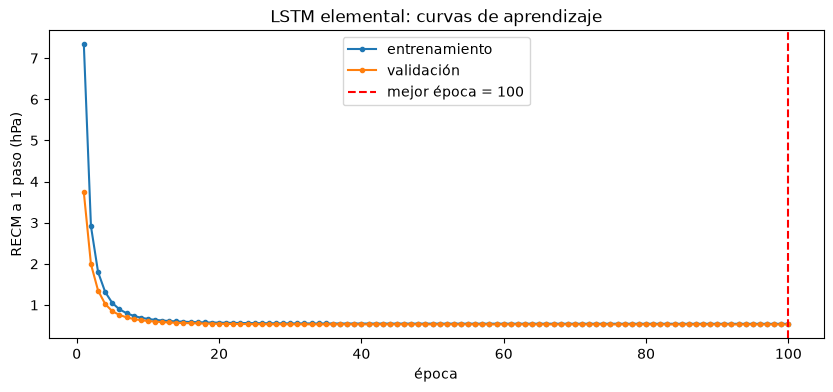

"validación (hPa), 2 pasos con estrategia recursiva",RECM 1 paso,RECM 2 pasos,EAM 1 paso,EAM 2 pasos
persistencia,0.6887,1.0848,0.4278,0.7779
MLP lineal 1x64,0.5917,0.8418,0.4693,0.6665
MLP elemental,0.5650,0.7774,0.4450,0.6113
LSTM elemental,0.5258,0.6839,0.4016,0.5318


In [43]:
historia_lstm_elemental = entrenar_con_validacion(lstm_elemental, W_train, Y_train[:, 0], W_val, Y_val[:, 0])
EPOCAS_LSTM_ELEMENTAL = historia_lstm_elemental["val_loss"].idxmin()
graficar_historia(historia_lstm_elemental, "LSTM elemental: curvas de aprendizaje")

pred_val_lstm_elemental = pronostico_recursivo(lstm_elemental, W_val, F_t[i_val], es_lstm=True)     # (1 paso, 2 pasos recursivo) en hPa
tabla_metricas({**referencias_val,
                "MLP elemental": evaluar_2pasos(y_val_h1, y_val_h2, *pred_val_mlp_elemental),
                "LSTM elemental": evaluar_2pasos(y_val_h1, y_val_h2, *pred_val_lstm_elemental)}, "validación").round(4)

**¿Qué observamos?**

- Con solo 521 parámetros, la LSTM elemental es el **mejor modelo en validación** a 1 paso (RECM ≈ 0.526, frente a ≈ 0.565 del MLP elemental y ≈ 0.592 del MLP lineal), y también a 2 pasos (≈ 0.684, frente a ≈ 0.777 y ≈ 0.842). Leer la ventana hora por hora, con los mismos pesos en cada paso, es una buena estructura para datos secuenciales.
- La curva de validación sigue bajando lentamente y el entrenamiento llegó al máximo de `EPOCAS_MAX` épocas sin que actuara la parada temprana: con tasa 0.001 la LSTM **aprende despacio**. Esto será importante en la búsqueda de hiperparámetros.

## 7.3 Paso 2: búsqueda de hiperparámetros con Hyperband

Entrenar una LSTM es más costoso, así que en lugar de probar toda la malla con muchas épocas usamos **Hyperband**:

1. Entrena **muchas** combinaciones durante **pocas** épocas.
2. Conserva la mejor tercera parte (`factor=3`) y las sigue entrenando con más épocas.
3. Repite hasta llegar a `max_epochs`.

Así el tiempo se dedica a las combinaciones prometedoras.

| Hiperparámetro | Valores |
|---|---|
| Número de capas LSTM | 1, 2 |
| Unidades por capa | 16, 32, 64 |
| Tasa de aprendizaje | 0.001, 0.01 |

In [44]:
def construir_lstm(hp):
    n_capas = hp.Choice("n_capas", [1, 2])
    unidades = hp.Choice("unidades", [16, 32, 64])
    tasa = hp.Choice("tasa", [1e-3, 1e-2])
    return crear_lstm(capas=(unidades,) * n_capas, tasa=tasa)

buscador_lstm = kt.Hyperband(construir_lstm, objective="val_loss", max_epochs=12, factor=3, seed=SEMILLA, overwrite=True,
                             directory="busqueda_hiperparametros", project_name="lstm")
buscador_lstm.search(W_train, Y_train[:, 0], validation_data=(W_val, Y_val[:, 0]), batch_size=LOTE,
                     callbacks=[parada_temprana(3)], verbose=0)

resultados_lstm = tabla_busqueda(buscador_lstm)
resultados_lstm.round(4)

,n_capas,unidades,tasa,RECM validación 1 paso
0,2,64,0.010,0.5549
1,1,64,0.010,0.5552
2,1,16,0.010,0.5610
3,2,16,0.010,0.5816
4,1,32,0.010,0.5917
5,2,32,0.010,0.6108
6,2,64,0.001,0.6927
7,1,64,0.001,0.7047
8,1,32,0.001,0.7191
9,2,32,0.001,0.7999


**¿Qué observamos?**

- Las mejores combinaciones usan tasa 0.01, y todas las de tasa 0.001 quedan al final de la tabla.
- **Esto no significa que 0.001 sea mala.** La LSTM elemental, con tasa 0.001, logró una RECM de validación a 1 paso ≈ 0.526, pero necesitó unas 100 épocas. Hyperband da como máximo 12 épocas por combinación, así que **favorece a los modelos que aprenden rápido**.
- Ninguna combinación de la búsqueda mejora a la LSTM elemental en validación.
- **Lección:** el resultado de una búsqueda depende del presupuesto de épocas que se le da. Por eso es útil tener siempre un modelo elemental como referencia.

## 7.4 Paso 3: validación cruzada secuencial

Mismos pliegues que en la sección 6.5. Candidatos: la LSTM elemental y las 2 mejores combinaciones de Hyperband.

In [45]:
def describir_lstm(hp):
    return f"LSTM {int(hp['n_capas'])}x{int(hp['unidades'])}, tasa={hp['tasa']}"

candidatos_lstm = {"LSTM elemental 1x8, tasa=0.001": dict(capas=(8,), tasa=1e-3)}
for _, hp in resultados_lstm.head(2).iterrows():
    candidatos_lstm[describir_lstm(hp)] = dict(capas=(int(hp["unidades"]),) * int(hp["n_capas"]), tasa=hp["tasa"])

cv_lstm = {}
for nombre, config in candidatos_lstm.items():
    modelo = crear_lstm(**config)
    historia = entrenar_con_validacion(modelo, W_train, Y_train[:, 0], W_val, Y_val[:, 0])
    epocas = int(historia["val_loss"].idxmin())
    cv_lstm[nombre] = {"pliegues": recm_pliegues(red_con_epocas(lambda: crear_lstm(**config), epocas), W_train, Y_train[:, 0]),
                       "RECM validación 1 paso": np.sqrt(historia["val_loss"].min()) * DE,
                       "épocas": epocas}
    print(f"{nombre}: listo ({epocas} épocas)")

resultados_cv_lstm = tabla_cv({**cv_lstm, **cv_referencias})
resultados_cv_lstm.round(4)

LSTM elemental 1x8, tasa=0.001: listo (100 épocas)
LSTM 2x64, tasa=0.01: listo (2 épocas)
LSTM 1x64, tasa=0.01: listo (3 épocas)


"validación cruzada, 1 paso (hPa)",pliegue 1,pliegue 2,pliegue 3,pliegue 4,RECM_cv 1 paso,RECM validación 1 paso,épocas
"LSTM elemental 1x8, tasa=0.001",0.5735,0.5022,0.5369,0.5774,0.5484,0.5258,100.0
"LSTM 1x64, tasa=0.01",0.6262,0.5605,0.5851,0.6138,0.5969,0.5586,3.0
"LSTM 2x64, tasa=0.01",0.6998,0.5979,0.6039,0.6340,0.6352,0.5644,2.0
MLP lineal 1x64,0.6672,0.5660,0.5873,0.8004,0.6617,NaN,42.0
persistencia,0.7414,0.5925,0.7004,0.7576,0.7009,NaN,NaN


In [46]:
nombre_lstm = resultados_cv_lstm.drop(index=list(cv_referencias)).index[0]
CONFIG_LSTM = candidatos_lstm[nombre_lstm]
EPOCAS_LSTM = int(resultados_cv_lstm.loc[nombre_lstm, "épocas"])
print("LSTM elegida por validación cruzada:", nombre_lstm, "|", EPOCAS_LSTM, "épocas")
print("LSTM elegida por validación simple: ", resultados_cv_lstm.drop(index=list(cv_referencias))["RECM validación 1 paso"].astype(float).idxmin())

LSTM elegida por validación cruzada: LSTM elemental 1x8, tasa=0.001 | 100 épocas
LSTM elegida por validación simple:  LSTM elemental 1x8, tasa=0.001


**¿Qué aprendimos?**

1. **La validación cruzada confirma la elección.** La LSTM elemental tiene la menor RECM_cv a 1 paso (≈ 0.548) y es mejor que el MLP lineal y que la persistencia **en los 4 pliegues**.
2. **Las combinaciones de Hyperband son inestables.** Con tasa 0.01 alcanzan su mejor error de validación en la época 2 o 3, y después el error sube. Entrenan rápido, pero no llegan tan lejos.
3. **El modelo final es la LSTM elemental.** Empezar con un modelo sencillo no fue solo un trámite: resultó ser el mejor candidato.

## 7.5 Paso 4: modelo final y evaluación en prueba

Reentrenamos la LSTM elegida con entrenamiento + validación y la evaluamos una sola vez en prueba. Como en la sección 6.6, el pronóstico a 2 pasos se obtiene con la estrategia recursiva (sección 4.3).

In [47]:
lstm_final = crear_lstm(**CONFIG_LSTM)
lstm_final.fit(W_train_val, Y_train_val[:, 0], epochs=EPOCAS_LSTM, batch_size=LOTE, verbose=0)
pred_test_lstm, pred_test_lstm_h2 = pronostico_recursivo(lstm_final, W_test, F_t[i_test], es_lstm=True)   # 1 paso y 2 pasos (recursivo), en hPa

prueba[f"LSTM final ({nombre_lstm})"] = evaluar_2pasos(y_test_h1, y_test_h2, pred_test_lstm, pred_test_lstm_h2)
tabla_metricas(prueba, "prueba").round(4)

"prueba (hPa), 2 pasos con estrategia recursiva",RECM 1 paso,RECM 2 pasos,EAM 1 paso,EAM 2 pasos
persistencia,0.6730,1.0503,0.4142,0.7524
MLP lineal 1x64,0.5592,0.7623,0.4431,0.5960
"MLP final (MLP 2x16 relu, tasa=0.001)",0.5580,0.7596,0.4362,0.5898
"LSTM final (LSTM elemental 1x8, tasa=0.001)",0.5249,0.6842,0.4081,0.5288


**¿Qué observamos en prueba?** (2 pasos con la estrategia recursiva)

- **La LSTM es el mejor modelo en los dos horizontes.** A 1 paso tiene RECM ≈ 0.525 hPa, aproximadamente 22% mejor que la persistencia (≈ 0.673). A 2 pasos tiene RECM ≈ 0.684, frente a ≈ 1.050 de la persistencia.
- **El MLP final (el elemental) y el MLP lineal quedan prácticamente empatados**: a 1 paso, RECM ≈ 0.558 y ≈ 0.559; a 2 pasos, ≈ 0.757 y ≈ 0.762. La ventaja del MLP no lineal en la validación cruzada (RECM_cv a 1 paso ≈ 0.623 frente a ≈ 0.662) no se tradujo en una mejora en prueba. Las redes que tratan la ventana como una fila plana de 168 números **no logran sacar provecho de la no linealidad**. La LSTM, que lee la ventana como una secuencia, sí mejora.
- A 1 paso, en el EAM la persistencia (≈ 0.414) es mejor que los dos MLP (≈ 0.44) y queda muy cerca de la LSTM (≈ 0.408). A 2 pasos ya no: su EAM (≈ 0.752) es mucho mayor que el de las redes (≈ 0.53–0.60). Como los datos están redondeados, en muchas horas la presión no cambia y la persistencia acierta exactamente. Las redes ganan sobre todo en las horas con **cambios grandes**, que la RECM penaliza más.

> ✏️ **Ejercicio 6.** Entrene la LSTM elegida usando como entrada **solo la presión** (`W_train[:, :, :1]`), sin las variables de Fourier. ¿Cuánto aportan los rezagos de Fourier? Haga lo mismo con el MLP (use solo las columnas `lag_k`).

# 8. Pronóstico 2 pasos adelante: recursivo, directo y *one-shot*

Desde el origen $t-1$ (último dato observado) queremos pronosticar $y_t$ (1 paso) y $y_{t+1}$ (2 pasos). Hay tres estrategias:

| | **Recursiva** | **Directa** | ***One-shot*** (MIMO) |
|---|---|---|---|
| Modelos | 1 (el de 1 paso) | 1 por horizonte: 2 | 1 red con **2 salidas** |
| $\hat y_t$ | $f(\text{ventana})$ | $f_1(\text{ventana})$ | primera salida de $g(\text{ventana})$ |
| $\hat y_{t+1}$ | $f(\text{ventana desplazada con } \color{red}{\hat y_t})$ | $f_2(\text{ventana})$ | segunda salida de $g(\text{ventana})$ |
| Respuesta al entrenar | `y_h1` | `y_h1` y `y_h2` por separado | `[y_h1, y_h2]` a la vez |

- **Recursiva:** reutiliza su propia predicción como `lag_1`. Los errores se acumulan.
- **Directa:** no reutiliza predicciones, pero entrena un modelo por cada horizonte.
- ***One-shot*** (*Multiple Input, Multiple Output*): una sola red produce todo el vector de pronósticos. Los horizontes comparten las capas ocultas y la red se entrena una sola vez. Es una estrategia muy natural en redes neuronales.

Para comparar de forma justa, las tres estrategias usan los **hiperparámetros y épocas elegidos** en las secciones 6 y 7, se entrenan con **entrenamiento + validación** y se evalúan en **todo el conjunto de prueba**.

## 8.1 Estrategia recursiva

Para pronosticar el segundo paso hay que construir la ventana de la hora $t+1$:

1. Se **elimina** el paso más antiguo de la ventana ($t-24$).
2. Se **agrega** un paso nuevo para la hora $t$ con la presión **pronosticada** $\hat y_t$ y las variables de Fourier **en la hora $t$**, que se conocen exactamente porque son determinísticas.

Esta es la estrategia que usamos desde la sección 4.3 para reportar los errores a 2 pasos: las funciones `ventana_siguiente` y `pronostico_recursivo` se definieron allí. Primero verificamos que la ventana se desliza correctamente.

In [50]:
# Verificación: si en lugar de la predicción usamos el valor REAL y_t, la ventana desplazada debe ser
# exactamente la ventana de la fila siguiente de la tabla.
W_desplazada = ventana_siguiente(W_test[:-1], Y_test[:-1, 0], F_t[i_test][:-1])
print("La ventana desplazada coincide con la de la fila siguiente:", np.allclose(W_desplazada, W_test[1:]))

La ventana desplazada coincide con la de la fila siguiente: True


In [51]:
pronosticos = {}           # (red, estrategia) -> (pred_h1, pred_h2) en hPa
pronosticos[("MLP", "recursiva")] = pronostico_recursivo(mlp_final, W_test, F_t[i_test], es_lstm=False)
pronosticos[("LSTM", "recursiva")] = pronostico_recursivo(lstm_final, W_test, F_t[i_test], es_lstm=True)

## 8.2 Estrategia directa

El modelo de 1 paso ($f_1$) es el modelo final de las secciones 6.6 y 7.5. Entrenamos un segundo modelo ($f_2$), con la **misma arquitectura y épocas**, cuya respuesta es `y_h2` $= y_{t+1}$. Por facilidad acá se entrena un modelo sin búsqueda de los mejores hiper-parámetros, se usan los del $f_1$, pero deberían buscarse los mejores para ese modelo.

In [52]:
mlp_h2 = crear_mlp(**CONFIG_MLP)
mlp_h2.fit(X_train_val, Y_train_val[:, 1], epochs=EPOCAS_MLP, batch_size=LOTE, verbose=0)
pronosticos[("MLP", "directa")] = (pred_test_mlp, a_hpa(mlp_h2.predict(X_test, verbose=0).ravel()))

lstm_h2 = crear_lstm(**CONFIG_LSTM)
lstm_h2.fit(W_train_val, Y_train_val[:, 1], epochs=EPOCAS_LSTM, batch_size=LOTE, verbose=0)
pronosticos[("LSTM", "directa")] = (pred_test_lstm, a_hpa(lstm_h2.predict(W_test, verbose=0).ravel()))

## 8.3 Estrategia *one-shot*

La misma arquitectura que antes tanto para la MLP como para la LSTM, pero con una capa de salida de **2 neuronas**. La función de pérdida es el promedio del ECM de las dos salidas. Deberían optimizarse los hiper-parámetros

In [53]:
mlp_2salidas = crear_mlp(**CONFIG_MLP, n_salidas=2)
mlp_2salidas.summary()
mlp_2salidas.fit(X_train_val, Y_train_val, epochs=EPOCAS_MLP, batch_size=LOTE, verbose=0)
p = mlp_2salidas.predict(X_test, verbose=0)
pronosticos[("MLP", "one-shot")] = (a_hpa(p[:, 0]), a_hpa(p[:, 1]))

lstm_2salidas = crear_lstm(**CONFIG_LSTM, n_salidas=2)
lstm_2salidas.fit(W_train_val, Y_train_val, epochs=EPOCAS_LSTM, batch_size=LOTE, verbose=0)
p = lstm_2salidas.predict(W_test, verbose=0)
pronosticos[("LSTM", "one-shot")] = (a_hpa(p[:, 0]), a_hpa(p[:, 1]))

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_27 (Dense)                │ (None, 16)             │         2,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,010 (11.76 KB)

 Trainable params: 3,010 (11.76 KB)

 Non-trainable params: 0 (0.00 B)

## 8.4 Comparación en prueba (1 y 2 pasos)

In [54]:
filas = {("Referencia", "persistencia"): evaluar_2pasos(y_test_h1, y_test_h2, pred_test_persistencia, pred_test_persistencia)}
for (red, estrategia), (p1, p2) in pronosticos.items():
    filas[(red, estrategia)] = evaluar_2pasos(y_test_h1, y_test_h2, p1, p2)
comparacion_2pasos = tabla_metricas(filas, "prueba", estrategia=None)     # la estrategia está en cada fila
comparacion_2pasos.index.names = ["red", "estrategia"]
comparacion_2pasos.round(4)

,prueba (hPa),RECM 1 paso,RECM 2 pasos,EAM 1 paso,EAM 2 pasos
red,estrategia,,,,
Referencia,persistencia,0.6730,1.0503,0.4142,0.7524
MLP,recursiva,0.5580,0.7596,0.4362,0.5898
LSTM,recursiva,0.5249,0.6842,0.4081,0.5288
MLP,directa,0.5580,0.7746,0.4362,0.6036
LSTM,directa,0.5249,0.6820,0.4081,0.5271
MLP,one-shot,0.6093,0.7430,0.4774,0.5781
LSTM,one-shot,0.5250,0.6834,0.4082,0.5279


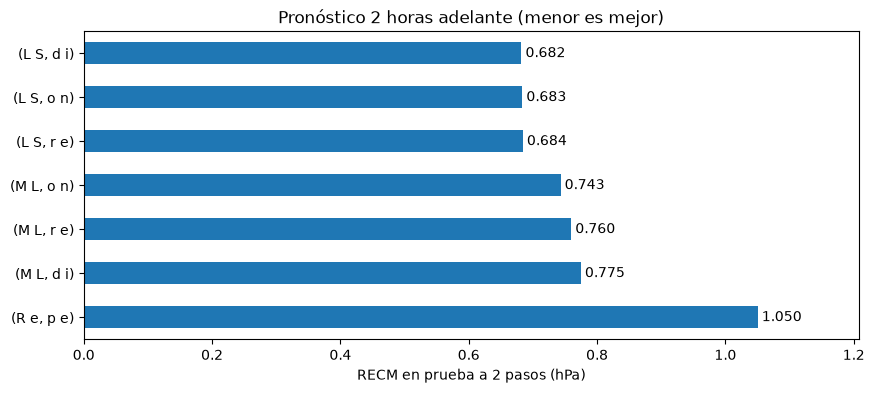

In [55]:
ax = comparacion_2pasos["RECM 2 pasos"].sort_values(ascending=False).rename(lambda t: f"{t[0]} {t[1]}").plot.barh(color="tab:blue")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set_xlabel("RECM en prueba a 2 pasos (hPa)"); ax.set_title("Pronóstico 2 horas adelante (menor es mejor)")
ax.set_xlim(0, comparacion_2pasos["RECM 2 pasos"].max() * 1.15); ax.set_ylabel(""); plt.show()

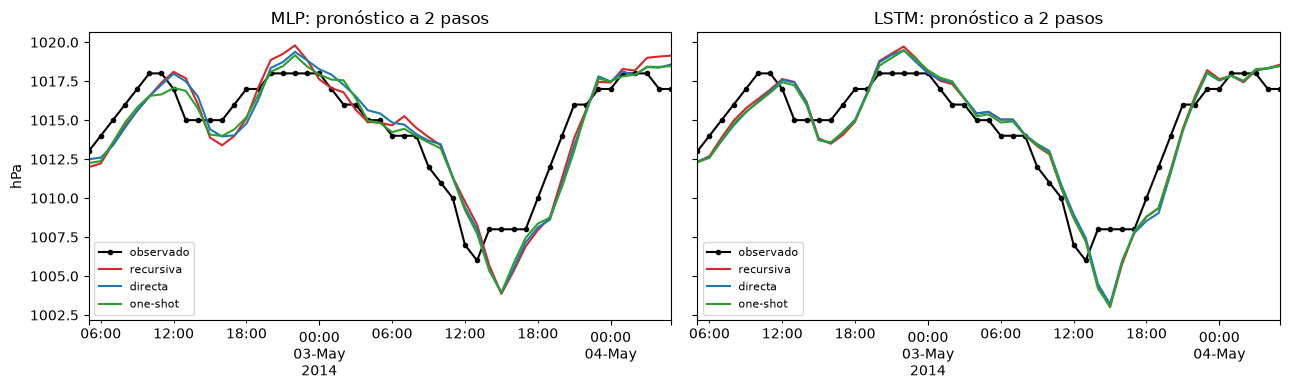

In [56]:
# Pronósticos a 2 pasos durante dos días del conjunto de prueba (cada punto se pronosticó 2 horas antes)
fechas_h2 = datos.index[i_test] + pd.Timedelta(hours=1)          # la fecha que se pronostica a 2 pasos es t+1
desde, hasta = fechas_h2[24 * 30], fechas_h2[24 * 32]

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, red in zip(ax, ["MLP", "LSTM"]):
    pd.Series(y_test_h2.values, index=fechas_h2)[desde:hasta].plot(ax=a, color="black", marker=".", label="observado")
    for estrategia, color in [("recursiva", "tab:red"), ("directa", "tab:blue"), ("one-shot", "tab:green")]:
        pd.Series(pronosticos[(red, estrategia)][1], index=fechas_h2)[desde:hasta].plot(ax=a, color=color, label=estrategia)
    a.set_title(f"{red}: pronóstico a 2 pasos"); a.set_ylabel("hPa"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**¿Qué observamos?**

- **El error crece con el horizonte** (todas las cifras son de prueba). La persistencia pasa de 0.67 a 1.05 hPa (+56%). Las tres estrategias con LSTM pasan de ≈ 0.525 a ≈ 0.683 hPa (+30%). Todas las estrategias superan claramente a la persistencia a 2 pasos.
- **Con la LSTM, las tres estrategias son prácticamente iguales** (RECM a 2 pasos entre 0.682 y 0.684). La recursiva casi no acumula error por dos razones: el error a 1 paso es pequeño frente a la variación de la serie, y las variables de Fourier de la hora $t$ se conocen exactamente, así que solo `lag_1` es una predicción.
- **Con el MLP las tres estrategias también quedan muy cerca a 2 pasos** (RECM: *one-shot* ≈ 0.755, recursiva ≈ 0.757, directa ≈ 0.758). La diferencia está a 1 paso: la *one-shot* es la peor (≈ 0.570 frente a ≈ 0.558). Las dos salidas comparten las capas ocultas y las épocas se eligieron para 1 paso, así que la red queda en un compromiso entre ambos horizontes.
- **La recursiva y la directa tienen el mismo error a 1 paso por construcción**, porque ambas usan el mismo modelo $f_1$. Las filas "recursiva" coinciden con las de los modelos finales en las secciones 6.6 y 7.5.
- **Costo computacional:** la recursiva entrena 1 modelo, la directa 1 por horizonte y la *one-shot* 1 modelo con varias salidas. Con horizontes largos, la directa se vuelve costosa.

> ✏️ **Ejercicio 7 (3 pasos adelante).** (a) Agregue la columna `y_h3` $= y_{t+2}$ a la tabla (recuerde eliminar una fila más al final). (b) Extienda `pronostico_recursivo` para un tercer paso aplicando `ventana_siguiente` dos veces. (c) Entrene el modelo directo $f_3$ y una red *one-shot* con 3 salidas. ¿Cómo crece la RECM con el horizonte en cada estrategia?
>
> ✏️ **Ejercicio 8.** En esta sección los modelos directo y *one-shot* reutilizaron los hiperparámetros elegidos para 1 paso. Repita la búsqueda de la sección 6.4 con la respuesta `y_h2`. ¿Se eligen los mismos hiperparámetros?

# 9. Etapa de producción: pronóstico de las 2 horas siguientes

Ya elegimos los modelos y medimos su desempeño en prueba. Para **usarlos en la práctica**:

1. Elegimos la red con **menor RECM en la validación cruzada** (secciones 6.5 y 7.4). La prueba no se usa para elegir.
2. Reentrenamos con **todas las observaciones** (entrenamiento + validación + prueba), con los mismos hiperparámetros y épocas.
3. Construimos la ventana con las **últimas 24 horas** de la serie y pronosticamos las 2 horas siguientes al último dato con las tres estrategias.

> La media y la desviación estándar de la estandarización se mantienen (las del entrenamiento): son parte del modelo.

In [57]:
recm_cv_mlp = resultados_cv_mlp.loc[nombre_mlp, "RECM_cv 1 paso"]
recm_cv_lstm = resultados_cv_lstm.loc[nombre_lstm, "RECM_cv 1 paso"]
RED_PROD = "MLP" if recm_cv_mlp <= recm_cv_lstm else "LSTM"
print(f"RECM_cv 1 paso  MLP: {recm_cv_mlp:.4f}  |  LSTM: {recm_cv_lstm:.4f}  ->  red de producción: {RED_PROD}")

if RED_PROD == "MLP":
    crear, config, epocas, entrada = crear_mlp, CONFIG_MLP, EPOCAS_MLP, (lambda W: W.reshape(len(W), -1))
else:
    crear, config, epocas, entrada = crear_lstm, CONFIG_LSTM, EPOCAS_LSTM, (lambda W: W)

W_todo = a_ventanas(X_todo)
prod_h1 = crear(**config);              prod_h1.fit(entrada(W_todo), Y_todo[:, 0], epochs=epocas, batch_size=LOTE, verbose=0)
prod_h2 = crear(**config);              prod_h2.fit(entrada(W_todo), Y_todo[:, 1], epochs=epocas, batch_size=LOTE, verbose=0)
prod_2s = crear(**config, n_salidas=2); _ = prod_2s.fit(entrada(W_todo), Y_todo,   epochs=epocas, batch_size=LOTE, verbose=0)

RECM_cv 1 paso  MLP: 0.6152  |  LSTM: 0.5484  ->  red de producción: LSTM


In [58]:
fechas_pronostico = pd.date_range(pres.index[-1] + pd.Timedelta(hours=1), periods=2, freq="h")
print(f"Último dato observado: {pres.index[-1]}  ->  pronosticamos: {fechas_pronostico[0]} y {fechas_pronostico[1]}")

# Ventana nueva: las últimas 24 horas observadas, presión estandarizada + variables de Fourier
ultimas = serie_y_fourier.iloc[-VENTANA:].copy()
ultimas["pres"] = (ultimas["pres"] - MEDIA) / DE
W_nueva = ultimas[VARIABLES].to_numpy("float32")[None, :, :]          # forma (1, 24, 7)

# Fourier de la primera hora pronosticada (necesaria para la estrategia recursiva)
F_nueva = variables_fourier(fechas_pronostico[:1]).to_numpy("float32")

p_rec = pronostico_recursivo(prod_h1, W_nueva, F_nueva, es_lstm=(RED_PROD == "LSTM"))
p_dir = (a_hpa(prod_h1.predict(entrada(W_nueva), verbose=0).ravel()), a_hpa(prod_h2.predict(entrada(W_nueva), verbose=0).ravel()))
p_2s = a_hpa(prod_2s.predict(entrada(W_nueva), verbose=0))[0]

pronostico_produccion = pd.DataFrame({"recursiva": [p_rec[0][0], p_rec[1][0]],
                                      "directa": [p_dir[0][0], p_dir[1][0]],
                                      "one-shot": [p_2s[0], p_2s[1]]}, index=fechas_pronostico)
pronostico_produccion.index.name = "hora pronosticada"
pronostico_produccion.round(3)

Último dato observado: 2014-12-31 23:00:00  ->  pronosticamos: 2015-01-01 00:00:00 y 2015-01-01 01:00:00


,recursiva,directa,one-shot
hora pronosticada,,,
2015-01-01 00:00:00,1034.052,1034.052,1033.923
2015-01-01 01:00:00,1034.046,1033.904,1033.835


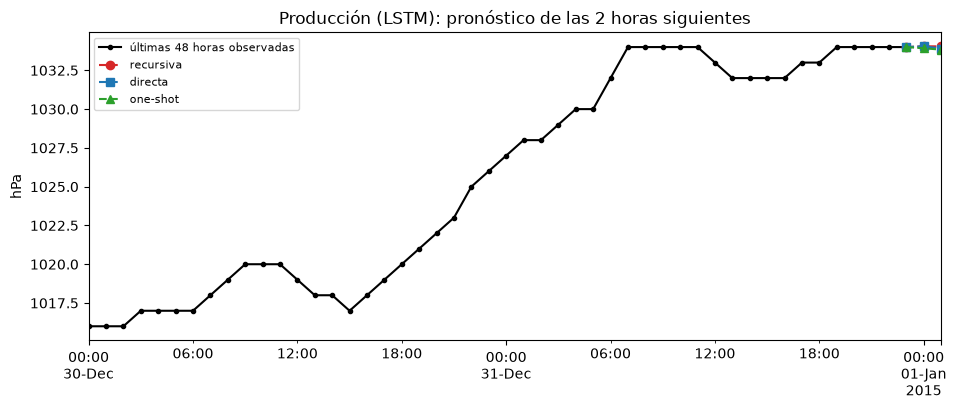

In [59]:
fig, ax = plt.subplots(figsize=(11, 4))
pres.iloc[-48:].plot(ax=ax, color="black", marker=".", label="últimas 48 horas observadas")
for estrategia, color, marca in [("recursiva", "tab:red", "o"), ("directa", "tab:blue", "s"), ("one-shot", "tab:green", "^")]:
    serie = pd.concat([pres.iloc[-1:], pronostico_produccion[estrategia]])
    serie.plot(ax=ax, color=color, marker=marca, ls="--", label=estrategia)
ax.set_title(f"Producción ({RED_PROD}): pronóstico de las 2 horas siguientes"); ax.set_ylabel("hPa"); ax.legend(fontsize=8)
plt.show()

> En producción no hay un valor real con el cual comparar: la evaluación ya se hizo en la sección 8.

> ✏️ **Ejercicio 9.** Suponga que se observa la presión de la primera hora pronosticada (invéntela, por ejemplo 1030 hPa). Sin reentrenar, construya la nueva ventana con `ventana_siguiente` (¡usando el valor real, estandarizado!) y pronostique las 2 horas siguientes con la estrategia *one-shot*.

# 10. Comparación final y conclusiones

## 10.1 Todos los modelos en prueba, 1 y 2 pasos adelante

Todos los modelos se entrenan con entrenamiento + validación y se evalúan en prueba, a 1 paso y a 2 pasos (estrategia recursiva). Para comparar con los modelos elementales, también los reentrenamos con entrenamiento + validación (con su número de épocas elegido en validación).

In [60]:
mlp_elemental_final = crear_mlp(capas=(8,))
mlp_elemental_final.fit(X_train_val, Y_train_val[:, 0], epochs=EPOCAS_MLP_ELEMENTAL, batch_size=LOTE, verbose=0)
lstm_elemental_final = crear_lstm(capas=(8,))
lstm_elemental_final.fit(W_train_val, Y_train_val[:, 0], epochs=EPOCAS_LSTM_ELEMENTAL, batch_size=LOTE, verbose=0)

# 2 pasos con la estrategia recursiva (sección 4.3), como los demás modelos de la tabla
prueba["MLP elemental"] = evaluar_2pasos(y_test_h1, y_test_h2, *pronostico_recursivo(mlp_elemental_final, X_test, F_t[i_test], es_lstm=False))
prueba["LSTM elemental"] = evaluar_2pasos(y_test_h1, y_test_h2, *pronostico_recursivo(lstm_elemental_final, W_test, F_t[i_test], es_lstm=True))

comparacion_modelos = tabla_metricas(prueba, "prueba").sort_values("RECM 1 paso")
for h in ["1 paso", "2 pasos"]:
    comparacion_modelos[f"mejora RECM {h} (%)"] = 100 * (1 - comparacion_modelos[f"RECM {h}"] / comparacion_modelos.loc["persistencia", f"RECM {h}"])
comparacion_modelos.round(4)

"prueba (hPa), 2 pasos con estrategia recursiva",RECM 1 paso,RECM 2 pasos,EAM 1 paso,EAM 2 pasos,mejora RECM 1 paso (%),mejora RECM 2 pasos (%)
"LSTM final (LSTM elemental 1x8, tasa=0.001)",0.5249,0.6842,0.4081,0.5288,21.9983,34.8528
LSTM elemental,0.5249,0.6842,0.4081,0.5288,21.9983,34.8528
MLP elemental,0.5578,0.7568,0.4391,0.5946,17.1127,27.9448
"MLP final (MLP 2x16 relu, tasa=0.001)",0.5580,0.7596,0.4362,0.5898,17.0828,27.6720
MLP lineal 1x64,0.5592,0.7623,0.4431,0.5960,16.9097,27.4128
persistencia,0.6730,1.0503,0.4142,0.7524,0.0000,0.0000


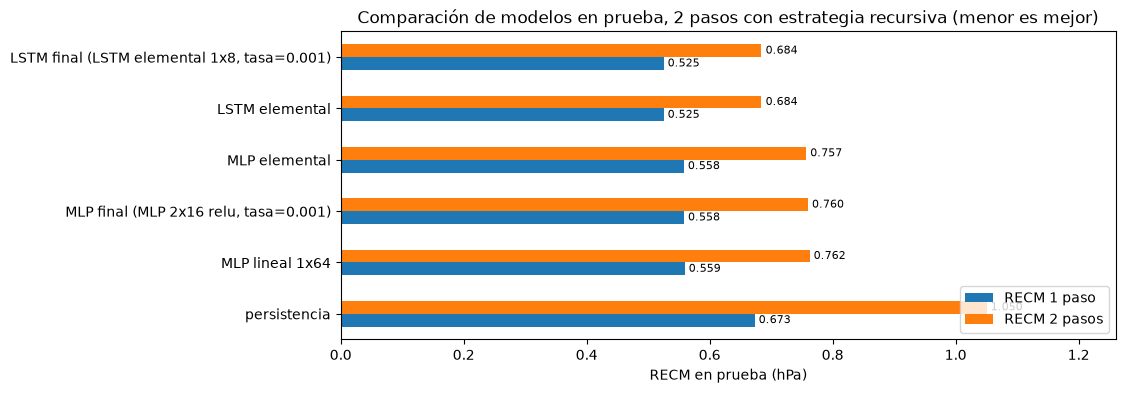

In [61]:
ax = comparacion_modelos[["RECM 1 paso", "RECM 2 pasos"]].iloc[::-1].plot.barh(color=["tab:blue", "tab:orange"])
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.3f", padding=3, fontsize=8)
ax.set_xlabel("RECM en prueba (hPa)"); ax.set_title("Comparación de modelos en prueba, 2 pasos con estrategia recursiva (menor es mejor)")
ax.set_xlim(0, comparacion_modelos["RECM 2 pasos"].max() * 1.2); ax.legend(loc="lower right")
plt.show()

## 10.2 Pronóstico 2 pasos adelante: las tres estrategias en prueba

In [62]:
comparacion_2pasos.round(4)

,prueba (hPa),RECM 1 paso,RECM 2 pasos,EAM 1 paso,EAM 2 pasos
red,estrategia,,,,
Referencia,persistencia,0.6730,1.0503,0.4142,0.7524
MLP,recursiva,0.5580,0.7596,0.4362,0.5898
LSTM,recursiva,0.5249,0.6842,0.4081,0.5288
MLP,directa,0.5580,0.7746,0.4362,0.6036
LSTM,directa,0.5249,0.6820,0.4081,0.5271
MLP,one-shot,0.6093,0.7430,0.4774,0.5781
LSTM,one-shot,0.5250,0.6834,0.4082,0.5279


## Conclusiones

1. **Diagnóstico → variables.** La PACF (estructura a lo largo de un día) justificó 24 rezagos de la presión. El periodograma (picos en 24 h, 12 h y un año) justificó las variables de Fourier. Evaluadas en cada hora de la ventana (los rezagos de Fourier), le dicen a la red **en qué hora del día y en qué época del año** está cada paso. No agregan información nueva sobre los ciclos (son colineales), pero le dan a la LSTM una entrada homogénea paso a paso.
2. **Siempre comparar con referencias.** La persistencia es difícil de superar en EAM. El **MLP con activaciones lineales** es la referencia para medir si la no linealidad aporta: aunque tiene 10 881 parámetros, equivale a un modelo lineal con 168 coeficientes. En prueba, el MLP no lineal **empató** con él; la LSTM lo superó claramente.
3. **Entrenar bien la referencia.** El MLP lineal necesitó más paciencia (20 épocas) que las demás redes. Con paciencia 5 se detenía en la época 7 y parecía peor que la persistencia. Una referencia mal entrenada hace que cualquier modelo parezca bueno.
4. **Primero un modelo elemental.** En las dos redes, la validación cruzada eligió el modelo elemental: el MLP de 8 neuronas y la LSTM de 8 unidades (521 parámetros, el mejor modelo de la clase). La búsqueda de hiperparámetros no los mejoró. Por eso en la tabla de la sección 10.1 las filas "MLP final" y "MLP elemental" coinciden, y también "LSTM final" y "LSTM elemental": son los mismos modelos. Más complejidad no significa más precisión.
5. **Validación simple vs. validación cruzada.** La validación simple fue optimista para todos los modelos. Para la LSTM, los dos criterios eligieron el mismo modelo. Para el MLP no: la validación simple eligió el 2×64 `tanh` y la validación cruzada el elemental, porque un solo bloque de validación puede favorecer a un modelo que no es el mejor en otras épocas del año. La validación cruzada mostró además cuánto cambia el error según la época del año.
6. **Búsqueda de hiperparámetros.** Hyperband es eficiente, pero con pocas épocas favorece a los modelos que aprenden rápido. El presupuesto de la búsqueda es, en sí mismo, una decisión de modelación.
7. **Pronóstico 2 pasos adelante.** Con la LSTM, recursiva, directa y *one-shot* dieron resultados prácticamente iguales. Con el MLP también quedaron muy cerca a 2 pasos, pero la *one-shot* empeoró a 1 paso. La recursiva aprovecha que las variables de Fourier del futuro se conocen exactamente.
8. **Producción.** La red se eligió con la validación cruzada (no con la prueba) y se reentrenó con todos los datos. Las tres estrategias pronostican alrededor de 1034 hPa para las dos primeras horas de 2015, con diferencias de unas 0.2 hPa como máximo (1034.05 frente a 1033.84 en la segunda hora).
9. **Siguientes pasos.** Entrenar la LSTM con más épocas, probar redes GRU, agregar otras variables meteorológicas del archivo (temperatura, punto de rocío, viento), pronosticar el cambio $y_t - y_{t-1}$ en lugar del nivel y construir intervalos de predicción.

# Anexo: compendio de funciones

Este anexo reúne las **24 funciones** definidas en el cuaderno. Para cada una se indica su objetivo, qué hace paso a paso, sus argumentos, qué devuelve y en qué secciones se usa. Están agrupadas según la etapa del flujo de trabajo:

| Grupo | Funciones |
|---|---|
| A. Evaluación | `evaluar`, `evaluar_2pasos`, `tabla_metricas` |
| B. Variables y transformaciones | `variables_fourier`, `a_hpa`, `a_ventanas` |
| C. Pronóstico recursivo | `ventana_siguiente`, `pronostico_recursivo` |
| D. Creación y entrenamiento de redes | `crear_mlp`, `crear_lstm`, `parada_temprana`, `entrenar_con_validacion`, `graficar_historia` |
| E. Búsqueda de hiperparámetros | `construir_mlp`, `construir_lstm`, `tabla_busqueda`, `describir_mlp`, `describir_lstm` |
| F. Validación cruzada secuencial | `recm_pliegues`, `red_con_epocas` (y su función interna `ajustar_y_predecir`), `persistencia_z`, `tabla_cv` |

**Variables globales.** Varias funciones usan constantes definidas en el cuaderno en lugar de recibirlas como argumentos. Si se copian a otro cuaderno, hay que definir también estas constantes:

| Constante | Valor | Dónde se define | Significado |
|---|---|---|---|
| `PERIODOS`, `ORIGEN` | 24 h, 12 h y 1 año; 2010-01-01 00:00 | Sección 2 | Periodos de los ciclos y origen del tiempo de las variables de Fourier |
| `VENTANA`, `N_VARS` | 24 y 7 | Sección 3 | Horas de historia y variables por hora (presión + 6 de Fourier) |
| `X_COLS` | 168 nombres | Sección 3 | Nombres de las columnas explicativas, en el orden de la tabla |
| `MEDIA`, `DE` | 1016.582 y 10.369 hPa | Sección 4.2 | Media y desviación estándar de la presión en entrenamiento |
| `SEMILLA` | 123 | Celda de librerías | Semilla para que los resultados sean reproducibles |
| `EPOCAS_MAX`, `LOTE` | 100 y 128 | Sección 6.1 | Máximo de épocas y tamaño del lote |
| `pliegues` | 4 pares de índices | Sección 6.5 | Índices de entrenamiento y validación de cada pliegue |

**Convención de unidades.** Las redes trabajan con la presión estandarizada (unidades $z$). Las métricas y los pronósticos que se muestran están siempre en **hPa**. La conversión la hace `a_hpa`.

## A. Evaluación

### `evaluar(y_real, y_pred)`

**Objetivo.** Medir el error de un conjunto de pronósticos siempre con las mismas dos métricas, para que todas las comparaciones del cuaderno sean equivalentes.

**Qué hace.** Calcula la RECM (`root_mean_squared_error`) y el EAM (`mean_absolute_error`) entre los valores reales y los pronosticados.

| Argumento | Tipo | Descripción |
|---|---|---|
| `y_real` | arreglo o `Series` | Valores observados, en hPa |
| `y_pred` | arreglo o `Series` | Valores pronosticados, en hPa, del mismo tamaño y en el mismo orden |

**Devuelve.** Un diccionario `{"RECM": ..., "EAM": ...}` en hPa.

**Dónde se usa.** Dentro de `evaluar_2pasos`, que es la que se usa en todas las tablas de error.

---

### `evaluar_2pasos(y_h1, y_h2, p1, p2)`

**Objetivo.** Medir el error de un modelo **a 1 paso y a 2 pasos adelante, desde el mismo origen** $t-1$, en una sola llamada.

**Qué hace.** Llama a `evaluar` dos veces: una con la respuesta a 1 paso ($y_t$) y su pronóstico, y otra con la respuesta a 2 pasos ($y_{t+1}$) y su pronóstico. Reorganiza los resultados en cuatro métricas con nombres explícitos.

| Argumento | Tipo | Descripción |
|---|---|---|
| `y_h1` | `Series` | Valores reales a 1 paso, $y_t$ (columna `y_h1` de la tabla), en hPa |
| `y_h2` | `Series` | Valores reales a 2 pasos, $y_{t+1}$ (columna `y_h2`), en hPa |
| `p1` | arreglo | Pronósticos a 1 paso, en hPa |
| `p2` | arreglo | Pronósticos a 2 pasos, en hPa |

**Devuelve.** Un diccionario con las claves `"RECM 1 paso"`, `"RECM 2 pasos"`, `"EAM 1 paso"` y `"EAM 2 pasos"`.

**Dónde se usa.** En todas las tablas de error: secciones 5, 6.2, 6.3, 6.6, 7.2, 7.5, 8.4 y 10.1. Suele recibir directamente la salida de `pronostico_recursivo` con un asterisco: `evaluar_2pasos(y_h1, y_h2, *pronostico_recursivo(...))`. El `*` separa la pareja `(p1, p2)` en dos argumentos.

---

### `tabla_metricas(filas, conjunto, estrategia="recursiva")`

**Objetivo.** Convertir los resultados de varios modelos en una tabla que diga **en su encabezado** si los errores son de validación o de prueba y con qué estrategia se obtuvo el pronóstico a 2 pasos.

**Qué hace.** Construye un `DataFrame` con una fila por modelo y escribe en el nombre de las columnas (la esquina superior izquierda de la tabla) el conjunto y la estrategia.

| Argumento | Tipo | Descripción |
|---|---|---|
| `filas` | diccionario | `{nombre del modelo: resultado de evaluar_2pasos(...)}` |
| `conjunto` | texto | `"validación"` o `"prueba"` |
| `estrategia` | texto o `None` | Estrategia usada para los 2 pasos (por defecto `"recursiva"`). Con `None` el encabezado no la menciona; se usa en la sección 8.4, donde cada fila tiene su propia estrategia |

**Devuelve.** Un `DataFrame` con las cuatro columnas de `evaluar_2pasos`.

**Dónde se usa.** Secciones 5, 6.2, 6.3, 6.6, 7.2, 7.5, 8.4 y 10.1.

## B. Variables y transformaciones

### `variables_fourier(fechas)`

**Objetivo.** Representar los ciclos diario (24 h y 12 h) y anual con variables **determinísticas**, que se pueden calcular para cualquier fecha, pasada o futura, sin pronosticarlas.

**Qué hace.**
1. Calcula las horas transcurridas desde `ORIGEN` (1 de enero de 2010, 00:00) hasta cada fecha.
2. Para cada periodo $P$ de `PERIODOS`, calcula $\sin(2\pi t/P)$ y $\cos(2\pi t/P)$.
3. Nombra las columnas `sin_24h`, `cos_24h`, `sin_12h`, `cos_12h`, `sin_anual` y `cos_anual`.

| Argumento | Tipo | Descripción |
|---|---|---|
| `fechas` | `DatetimeIndex` | Fechas horarias para las que se calculan las variables |

**Devuelve.** Un `DataFrame` con 6 columnas (seno y coseno de cada periodo), indexado por `fechas`.

**Dónde se usa.** Sección 2, para toda la serie. Sección 9 (producción), para la primera hora que se pronostica, que todavía no está en los datos.

---

### `a_hpa(z)`

**Objetivo.** Volver de la escala estandarizada en la que trabajan las redes a la escala original (hPa), para interpretar pronósticos y calcular métricas.

**Qué hace.** Aplica la transformación inversa de la estandarización: $y = z \cdot s_{\text{entrenamiento}} + \bar y_{\text{entrenamiento}}$, con `DE` y `MEDIA` calculadas solo con el conjunto de entrenamiento.

| Argumento | Tipo | Descripción |
|---|---|---|
| `z` | número o arreglo | Valores en unidades estandarizadas |

**Devuelve.** Un arreglo de NumPy en hPa.

**Dónde se usa.** Cada vez que una red produce un pronóstico: dentro de `pronostico_recursivo` y `recm_pliegues`, en las estrategias directa y *one-shot* (8.2 y 8.3) y en producción (9).

---

### `a_ventanas(X)`

**Objetivo.** Convertir la tabla plana que usa el MLP en el arreglo tridimensional que necesita la LSTM.

**Qué hace.** Reorganiza cada fila de 168 números en una matriz de 24 pasos de tiempo × 7 variables, con `reshape`. Funciona porque las columnas de la tabla están ordenadas por hora (de $t-24$ a $t-1$) y, dentro de cada hora, siempre en el mismo orden: presión y luego las seis variables de Fourier (sección 3).

| Argumento | Tipo | Descripción |
|---|---|---|
| `X` | arreglo `(n, 168)` | Tabla de variables explicativas |

**Devuelve.** Un arreglo `(n, 24, 7)`: muestras × pasos de tiempo × variables por paso.

**Dónde se usa.** Sección 7.1 (ventanas de entrenamiento, validación y prueba) y sección 9 (ventanas con todos los datos).

## C. Pronóstico recursivo

### `ventana_siguiente(W, y_nuevo_z, F_nuevo)`

**Objetivo.** Avanzar la ventana de historia una hora, que es la operación central de la estrategia recursiva.

**Qué hace.**
1. Arma un paso nuevo con la presión `y_nuevo_z` y las seis variables de Fourier `F_nuevo`.
2. Elimina el paso más antiguo de cada ventana ($t-24$).
3. Agrega el paso nuevo al final, como hora más reciente.

La sección 8.1 verifica la función: si se usa el valor **real** $y_t$, la ventana desplazada coincide exactamente con la ventana de la fila siguiente de la tabla.

| Argumento | Tipo | Descripción |
|---|---|---|
| `W` | arreglo `(n, 24, 7)` | Ventanas actuales (horas $t-24, \dots, t-1$) |
| `y_nuevo_z` | arreglo `(n,)` | Presión de la hora $t$ **en unidades estandarizadas**: el pronóstico $\hat y_t$ o, en el ejercicio 9, un valor observado |
| `F_nuevo` | arreglo `(n, 6)` | Variables de Fourier de la hora $t$ |

**Devuelve.** Un arreglo `(n, 24, 7)` con las ventanas de las horas $t-23, \dots, t$.

**Dónde se usa.** Dentro de `pronostico_recursivo` y en la verificación de la sección 8.1.

---

### `pronostico_recursivo(modelo, X, F_t, es_lstm)`

**Objetivo.** Obtener pronósticos **a 1 y a 2 pasos** con una red entrenada solo para 1 paso, sin entrenar otra red.

**Qué hace.**
1. Lleva la entrada a forma de ventanas `(n, 24, 7)`, venga de la tabla o ya en ventanas.
2. Pronostica $\hat y_t$ con la ventana original.
3. Construye la ventana siguiente con `ventana_siguiente`, poniendo $\hat y_t$ como presión de la hora $t$ y las variables de Fourier de la hora $t$, que se conocen exactamente.
4. Pronostica $\hat y_{t+1}$ con esa ventana y la **misma** red.
5. Convierte los dos pronósticos a hPa con `a_hpa`.

Si la red es un MLP, aplana cada ventana a 168 números antes de predecir. Si es una LSTM, le pasa la ventana tal cual.

| Argumento | Tipo | Descripción |
|---|---|---|
| `modelo` | red de Keras | Red entrenada para pronosticar 1 paso (`y_h1`) |
| `X` | arreglo `(n, 168)` o `(n, 24, 7)` | Variables explicativas: la tabla del MLP o las ventanas de la LSTM |
| `F_t` | arreglo `(n, 6)` | Variables de Fourier de la hora $t$ de cada fila. En el cuaderno, `F_t[i_val]` o `F_t[i_test]` |
| `es_lstm` | `True` / `False` | `True` si la red es una LSTM y `False` si es un MLP |

**Devuelve.** Una pareja `(p1, p2)` de arreglos en hPa: pronósticos a 1 paso ($\hat y_t$) y a 2 pasos ($\hat y_{t+1}$).

**Dónde se usa.** En todos los errores a 2 pasos de las redes (6.2, 6.3, 6.6, 7.2, 7.5 y 10.1), en la estrategia recursiva de la sección 8.1 y en producción (9).

## D. Creación y entrenamiento de redes

### `crear_mlp(capas=(8,), activacion="relu", tasa=1e-3, n_salidas=1)`

**Objetivo.** Construir y compilar un perceptrón multicapa con la arquitectura indicada, siempre con la misma inicialización.

**Qué hace.**
1. Fija la semilla (`keras.utils.set_random_seed(SEMILLA)`), así que dos redes con los mismos argumentos empiezan con los mismos pesos.
2. Crea una entrada de 168 variables (`VENTANA * N_VARS`).
3. Agrega una capa densa por cada elemento de `capas`, con la activación indicada.
4. Agrega una capa de salida **lineal** con `n_salidas` neuronas.
5. Compila con el optimizador Adam y pérdida ECM (`"mse"`).

| Argumento | Tipo | Descripción |
|---|---|---|
| `capas` | tupla de enteros | Neuronas de cada capa oculta. `(8,)` es una capa de 8; `(16, 16)` son dos capas de 16 |
| `activacion` | texto | Activación de las capas ocultas: `"relu"`, `"tanh"` o `"linear"` (el MLP lineal de 6.2) |
| `tasa` | número | Tasa de aprendizaje de Adam |
| `n_salidas` | entero | 1 para pronosticar un horizonte; 2 para la estrategia *one-shot* (8.3) |

**Devuelve.** Un modelo `keras.Sequential` compilado, sin entrenar.

**Dónde se usa.** En todas las secciones donde se entrena un MLP: 6.2 a 6.6, 8.2, 8.3, 9 y 10.1.

---

### `crear_lstm(capas=(8,), tasa=1e-3, n_salidas=1)`

**Objetivo.** Construir y compilar una red LSTM, siempre con la misma inicialización.

**Qué hace.**
1. Fija la semilla, igual que `crear_mlp`.
2. Crea una entrada de forma `(24, 7)`: 24 pasos de tiempo con 7 variables cada uno.
3. Agrega una capa LSTM por cada elemento de `capas`. Las capas intermedias devuelven la secuencia completa (`return_sequences=True`) para que la siguiente la lea paso a paso; la última devuelve solo su estado final.
4. Agrega una capa de salida lineal con `n_salidas` neuronas.
5. Compila con Adam y pérdida ECM.

| Argumento | Tipo | Descripción |
|---|---|---|
| `capas` | tupla de enteros | Unidades de cada capa LSTM |
| `tasa` | número | Tasa de aprendizaje de Adam |
| `n_salidas` | entero | 1 para un horizonte; 2 para la estrategia *one-shot* |

**Devuelve.** Un modelo `keras.Sequential` compilado, sin entrenar. La activación de la LSTM es la de defecto (`tanh`).

**Dónde se usa.** Secciones 7.2 a 7.5, 8.2, 8.3, 9 y 10.1.

---

### `parada_temprana(paciencia=5)`

**Objetivo.** Detener el entrenamiento cuando el error de validación deja de mejorar y quedarse con la mejor época.

**Qué hace.** Crea un *callback* `EarlyStopping` de Keras que vigila `val_loss`. Si no mejora durante `paciencia` épocas seguidas, detiene el entrenamiento y restaura los pesos de la mejor época (`restore_best_weights=True`).

| Argumento | Tipo | Descripción |
|---|---|---|
| `paciencia` | entero | Épocas sin mejora que se toleran antes de detener |

**Devuelve.** Un objeto `keras.callbacks.EarlyStopping`.

**Dónde se usa.** Dentro de `entrenar_con_validacion` y en las búsquedas de hiperparámetros (6.4 y 7.3), con paciencia 3.

---

### `entrenar_con_validacion(modelo, X_tr, y_tr, X_va, y_va, paciencia=5)`

**Objetivo.** Entrenar una red eligiendo el número de épocas con el conjunto de validación, y guardar la historia del entrenamiento.

**Qué hace.**
1. Entrena con `X_tr`, `y_tr` hasta `EPOCAS_MAX` épocas, en lotes de `LOTE`, calculando en cada época el error en `X_va`, `y_va`.
2. Usa `parada_temprana(paciencia)`.
3. Convierte la historia en una tabla con una fila por época, numeradas desde 1.

| Argumento | Tipo | Descripción |
|---|---|---|
| `modelo` | red de Keras | Red creada con `crear_mlp` o `crear_lstm`. Se modifica: queda entrenada |
| `X_tr`, `y_tr` | arreglos | Variables explicativas y respuesta de entrenamiento (estandarizadas) |
| `X_va`, `y_va` | arreglos | Variables explicativas y respuesta de validación |
| `paciencia` | entero | Paciencia de la parada temprana. El MLP lineal usa 20 (sección 6.2) |

**Devuelve.** Un `DataFrame` indexado por `época`, con las columnas `loss` (ECM de entrenamiento) y `val_loss` (ECM de validación), en unidades estandarizadas al cuadrado. La mejor época es `historia["val_loss"].idxmin()`.

**Dónde se usa.** 6.2, 6.3, 6.5, 7.2 y 7.4.

---

### `graficar_historia(historia, titulo)`

**Objetivo.** Ver cómo evoluciona el error durante el entrenamiento y en qué época se quedó la parada temprana.

**Qué hace.** Convierte el ECM estandarizado de cada época a RECM en hPa ($\sqrt{\text{ECM}} \cdot s$). Grafica las curvas de entrenamiento y validación y marca la mejor época con una línea roja punteada.

| Argumento | Tipo | Descripción |
|---|---|---|
| `historia` | `DataFrame` | Salida de `entrenar_con_validacion` |
| `titulo` | texto | Título del gráfico |

**Devuelve.** Nada: solo muestra el gráfico.

**Dónde se usa.** 6.2, 6.3 y 7.2.

## E. Búsqueda de hiperparámetros

### `construir_mlp(hp)`

**Objetivo.** Decirle a `keras_tuner` qué valores puede probar para cada hiperparámetro del MLP y cómo construir la red con una combinación.

**Qué hace.** Declara cuatro hiperparámetros con `hp.Choice`: número de capas (1 o 2), neuronas por capa (16 o 64), activación (`relu` o `tanh`) y tasa de aprendizaje (0.001 o 0.01). Luego construye la red con `crear_mlp`, usando el mismo número de neuronas en todas las capas.

| Argumento | Tipo | Descripción |
|---|---|---|
| `hp` | `keras_tuner.HyperParameters` | Objeto que entrega `keras_tuner`; no se crea a mano |

**Devuelve.** Un MLP compilado con la combinación elegida por el buscador.

**Dónde se usa.** Se le pasa a `kt.GridSearch` en la sección 6.4. El buscador la llama una vez por cada una de las 16 combinaciones.

---

### `construir_lstm(hp)`

**Objetivo.** Lo mismo que `construir_mlp`, para la LSTM.

**Qué hace.** Declara tres hiperparámetros: número de capas LSTM (1 o 2), unidades por capa (16, 32 o 64) y tasa de aprendizaje (0.001 o 0.01). Construye la red con `crear_lstm`.

| Argumento | Tipo | Descripción |
|---|---|---|
| `hp` | `keras_tuner.HyperParameters` | Objeto que entrega `keras_tuner` |

**Devuelve.** Una LSTM compilada con la combinación elegida por el buscador.

**Dónde se usa.** Se le pasa a `kt.Hyperband` en la sección 7.3.

---

### `tabla_busqueda(buscador)`

**Objetivo.** Resumir los resultados de una búsqueda en una tabla legible, con el error en hPa.

**Qué hace.**
1. Recorre los ensayos del buscador, del mejor al peor.
2. Para cada uno, toma sus hiperparámetros, sin los internos de `keras_tuner` que empiezan con `tuner/`.
3. Convierte su puntaje (el menor ECM de validación, estandarizado) a RECM en hPa.
4. Si una combinación aparece más de una vez, cosa que pasa con Hyperband, conserva solo su mejor resultado.

| Argumento | Tipo | Descripción |
|---|---|---|
| `buscador` | `kt.GridSearch` o `kt.Hyperband` | Buscador después de ejecutar `search` |

**Devuelve.** Un `DataFrame` con una fila por combinación, sus hiperparámetros y la columna `RECM validación 1 paso`, ordenado de menor a mayor error.

**Dónde se usa.** 6.4 y 7.3.

---

### `describir_mlp(hp)` y `describir_lstm(hp)`

**Objetivo.** Dar a cada candidato un nombre corto y legible para las tablas de la validación cruzada.

**Qué hacen.** Arman un texto con la arquitectura, por ejemplo `"MLP 2x64 tanh, tasa=0.001"` o `"LSTM 1x64, tasa=0.01"`.

| Argumento | Tipo | Descripción |
|---|---|---|
| `hp` | fila de `tabla_busqueda` | Debe tener las claves `n_capas`, `unidades` y `tasa`, además de `activacion` en el MLP |

**Devuelven.** Un texto.

**Dónde se usan.** 6.5 (`describir_mlp`) y 7.4 (`describir_lstm`).

## F. Validación cruzada secuencial

Las cuatro funciones de este grupo trabajan juntas. `recm_pliegues` recorre los pliegues y, en cada uno, llama a una función que **ajusta con unos datos y predice otros**. Esa función puede ser una red (`red_con_epocas`) o la persistencia (`persistencia_z`), así que el mismo código sirve para comparar todos los modelos. Al final, `tabla_cv` reúne los resultados.

### `recm_pliegues(ajustar_y_predecir, X, y)`

**Objetivo.** Calcular el error de un modelo en cada pliegue de la validación cruzada secuencial.

**Qué hace.** Para cada pliegue de `pliegues`:
1. Ajusta el modelo con las filas de entrenamiento del pliegue y predice las filas de validación, llamando a `ajustar_y_predecir`.
2. Convierte la predicción y los valores reales a hPa con `a_hpa` y calcula la RECM.

| Argumento | Tipo | Descripción |
|---|---|---|
| `ajustar_y_predecir` | función | Recibe `(X_tr, y_tr, X_va)` y devuelve predicciones estandarizadas para `X_va`. Por ejemplo, la salida de `red_con_epocas` o `persistencia_z` |
| `X` | arreglo | Variables explicativas de **entrenamiento** (`X_train` para el MLP, `W_train` para la LSTM) |
| `y` | arreglo | Respuesta a 1 paso de entrenamiento, estandarizada (`Y_train[:, 0]`) |

**Devuelve.** Una lista con 4 valores: la RECM a 1 paso, en hPa, de cada pliegue.

**Dónde se usa.** 6.5 y 7.4.

---

### `red_con_epocas(crear, epocas)`

**Objetivo.** Empaquetar "crear una red nueva, entrenarla un número fijo de épocas y predecir" en una función con la forma que espera `recm_pliegues`.

**Qué hace.** Devuelve una función interna, `ajustar_y_predecir(X_tr, y_tr, X_va)`, que en cada llamada:
1. Crea una red **nueva** con `crear()`, para que cada pliegue empiece desde cero y con la misma inicialización.
2. La entrena exactamente `epocas` épocas, sin parada temprana, porque dentro de los pliegues no hay un conjunto aparte para detenerla.
3. Devuelve sus predicciones para `X_va`.

| Argumento | Tipo | Descripción |
|---|---|---|
| `crear` | función sin argumentos | Construye la red, por ejemplo `lambda: crear_mlp(**config)` |
| `epocas` | entero | Número de épocas, elegido antes con `entrenar_con_validacion` |

**Devuelve.** La función `ajustar_y_predecir`.

**Dónde se usa.** 6.5 y 7.4.

---

### `persistencia_z(X_tr, y_tr, X_va)`

**Objetivo.** Expresar la persistencia con la misma forma que una red, para evaluarla con `recm_pliegues` en los mismos pliegues.

**Qué hace.** Devuelve la columna `lag_1` de `X_va`: el pronóstico es la última presión observada, en unidades estandarizadas. No usa `X_tr` ni `y_tr`, porque la persistencia no se ajusta, pero los recibe para tener la misma forma que las demás.

| Argumento | Tipo | Descripción |
|---|---|---|
| `X_tr`, `y_tr` | arreglos | Datos de entrenamiento del pliegue (no se usan) |
| `X_va` | arreglo `(n, 168)` | Tabla de validación del pliegue |

**Devuelve.** Un arreglo con `lag_1` de cada fila, estandarizado.

**Dónde se usa.** 6.5. Sus resultados se reutilizan como referencia en 7.4.

---

### `tabla_cv(resultados)`

**Objetivo.** Reunir los resultados de la validación cruzada de varios modelos en una tabla ordenada del mejor al peor.

**Qué hace.**
1. Pone en columnas la RECM de cada pliegue (`pliegue 1` a `pliegue 4`).
2. Calcula `RECM_cv 1 paso` promediando los ECM de los pliegues y sacando la raíz: $\sqrt{\tfrac{1}{4}\sum_k \text{RECM}_k^2}$. Es correcto porque todos los pliegues tienen el mismo tamaño.
3. Agrega las demás columnas que traiga cada modelo, como `RECM validación 1 paso` o `épocas`.
4. Ordena por `RECM_cv 1 paso` y escribe en el encabezado que son errores de validación cruzada a 1 paso.

| Argumento | Tipo | Descripción |
|---|---|---|
| `resultados` | diccionario | `{nombre del modelo: {"pliegues": [4 RECM], otras columnas...}}` |

**Devuelve.** Un `DataFrame` con una fila por modelo, ordenado de menor a mayor `RECM_cv 1 paso`. El primer modelo que no sea referencia es el elegido (secciones 6.5 y 7.4).

**Dónde se usa.** 6.5 y 7.4.